# 03 · 苍穹外卖：菜品管理

来源：本地 `讲义.rar / 讲义/day03/苍穹外卖-day03.md` 与 `PPT.rar / PPT/day03-菜品管理.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章接着员工管理、分类管理，先通过自定义注解与AOP统一填充公共字段，再实现图片上传、菜品新增、分页、删除、回显和修改。沿用前两章的格式，保留讲义的代码、表格与配图，按89页PPT核对章节；理解说明与勘误放在独立单元。配图已内嵌，可离线阅读。

跟练前需要已能启动三个Maven模块、连接初始化数据库、通过员工登录取得token，并具备第二章的分类接口。图片上传还需要自己的OSS Bucket、对应地域的Endpoint和访问凭据。Java、XML、YAML与SQL放在Markdown代码块中，供阅读与工程跟练。

> **本章重点勘误。** 讲义的 `updateWithFlavor` 缺少 `@Transactional`，PPT第84页带有该注解；修改菜品与替换口味必须处于同一个事务。原OSS工具类捕获上传异常后仍返回URL，会把失败当作成功；后面给出修正。讲义共47段代码，仅将YAML中的两条明文AccessKey示例替换为填写占位符，其余代码内容保留；源讲义未修改。


## 跟练路线、接口与数据关系（补充）

| 顺序 | 实现内容 | 需要掌握的关键点 |
| --- | --- | --- |
| 1 | 公共字段自动填充 | 注解说明操作类型，AOP在Mapper调用前设置审计字段 |
| 2 | 文件上传与新增菜品 | 先拿图片URL，再在事务内插入菜品与关联口味 |
| 3 | 菜品分页查询 | 可选条件、分类名称关联查询、PageHelper |
| 4 | 单个与批量删除 | 起售不能删、套餐关联不能删、口味同步删除 |
| 5 | 菜品回显与修改 | 回显全部口味，在事务内整体替换口味 |

### 接口速查

| 功能 | 方法与后端路径 | 参数与返回用途 |
| --- | --- | --- |
| 可用菜品分类 | `GET /admin/category/list?type=1` | 第二章已有；下拉框选择启用的菜品分类 |
| 图片上传 | `POST /admin/common/upload` | multipart字段file；返回图片URL |
| 新增菜品 | `POST /admin/dish` | JSON DishDTO，包含flavors |
| 分页查询 | `GET /admin/dish/page` | Query：page、pageSize、name、categoryId、status |
| 删除菜品 | `DELETE /admin/dish?ids=1,2` | Query：逗号分隔id列表，单删也使用此接口 |
| 菜品回显 | `GET /admin/dish/{id}` | Path：id；返回DishVO与口味集合 |
| 修改菜品 | `PUT /admin/dish` | JSON DishDTO，必须带目标id |

管理页面经过Nginx的 `/api/...` 入口转发到后端 `/admin/...`；Knife4j直接测试后端路径。受保护接口均需要携带课程约定的token请求头。菜品启停售的独立接口不在本章这五部分的实现范围内，不要从截图中的按钮推断已完成对应代码。

### 三类关联

```text
category.id  ←  dish.category_id
                 dish.id  ←  dish_flavor.dish_id
                 dish.id  ←  setmeal_dish.dish_id  →  setmeal.id
```

一个分类可以包含多个菜品，一个菜品可以有多条口味；套餐通过中间表关联菜品。本章表设计使用逻辑外键，关联关系由业务和SQL维护，不等于数据库已创建外键约束。

### 新增时的两个请求

```text
请求一：图片 → CommonController → AliOssUtil → OSS → 图片URL
请求二：菜品DTO（image=图片URL，flavors=口味列表）
        → DishService.saveWithFlavor
        → 插入dish并回填id → 给口味设置dishId → 批量插入dish_flavor
        → 数据库事务提交
```

上传与保存菜品是两个请求。图片URL放进dish.image；图片二进制保存在OSS，不存到dish表中。


## 课程内容

> **PPT对照：** 第1—3页。

- 公共字段自动填充
- 新增菜品
- 菜品分页查询
- 删除菜品
- 修改菜品


**功能实现：**菜品管理

**菜品管理效果图：**

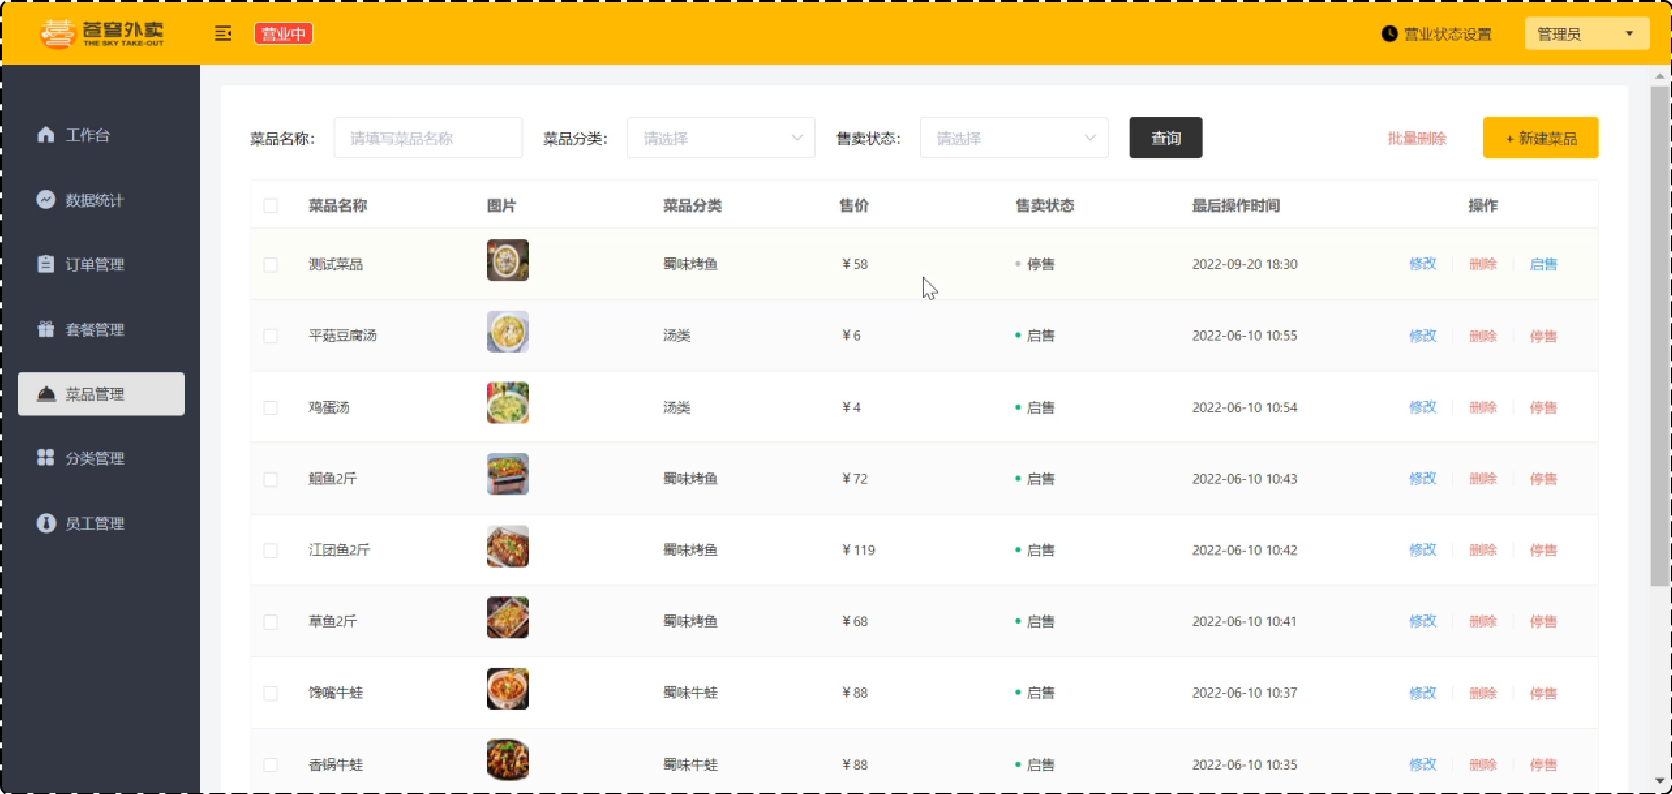


## 1. 公共字段自动填充

> **PPT对照：** 第4—17页。


### 1.1 问题分析

> **PPT对照：** 第5页。

在上一章节我们已经完成了后台系统的**员工管理功能**和**菜品分类功能**的开发，在**新增员工**或者**新增菜品分类**时需要设置创建时间、创建人、修改时间、修改人等字段，在**编辑员工**或者**编辑菜品分类**时需要设置修改时间、修改人等字段。这些字段属于公共字段，也就是也就是在我们的系统中很多表中都会有这些字段，如下：

| **序号** | **字段名**  | **含义** | **数据类型** |
| -------- | ----------- | -------- | ------------ |
| 1        | create_time | 创建时间 | datetime     |
| 2        | create_user | 创建人id | bigint       |
| 3        | update_time | 修改时间 | datetime     |
| 4        | update_user | 修改人id | bigint       |

而针对于这些字段，我们的赋值方式为： 

1). 在新增数据时, 将createTime、updateTime 设置为当前时间, createUser、updateUser设置为当前登录用户ID。

2). 在更新数据时, 将updateTime 设置为当前时间, updateUser设置为当前登录用户ID。


目前,在我们的项目中处理这些字段都是在每一个业务方法中进行赋值操作,如下:

**新增员工方法：**

```java
	/**
     * 新增员工
     *
     * @param employeeDTO
     */
    public void save(EmployeeDTO employeeDTO) {
        //.......................
		//////////////////////////////////////////
        //设置当前记录的创建时间和修改时间
        employee.setCreateTime(LocalDateTime.now());
        employee.setUpdateTime(LocalDateTime.now());

        //设置当前记录创建人id和修改人id
        employee.setCreateUser(BaseContext.getCurrentId());//目前写个假数据，后期修改
        employee.setUpdateUser(BaseContext.getCurrentId());
		///////////////////////////////////////////////
        employeeMapper.insert(employee);
    }
```

**编辑员工方法：**

```java
	/**
     * 编辑员工信息
     *
     * @param employeeDTO
     */
    public void update(EmployeeDTO employeeDTO) {
       //........................................
	   ///////////////////////////////////////////////
        employee.setUpdateTime(LocalDateTime.now());
        employee.setUpdateUser(BaseContext.getCurrentId());
       ///////////////////////////////////////////////////

        employeeMapper.update(employee);
    }
```

**新增菜品分类方法：**

```java
	/**
     * 新增分类
     * @param categoryDTO
     */
    public void save(CategoryDTO categoryDTO) {
       //....................................
       //////////////////////////////////////////
        //设置创建时间、修改时间、创建人、修改人
        category.setCreateTime(LocalDateTime.now());
        category.setUpdateTime(LocalDateTime.now());
        category.setCreateUser(BaseContext.getCurrentId());
        category.setUpdateUser(BaseContext.getCurrentId());
        ///////////////////////////////////////////////////

        categoryMapper.insert(category);
    }
```

**修改菜品分类方法：**

```java
	/**
     * 修改分类
     * @param categoryDTO
     */
    public void update(CategoryDTO categoryDTO) {
        //....................................
        
		//////////////////////////////////////////////
        //设置修改时间、修改人
        category.setUpdateTime(LocalDateTime.now());
        category.setUpdateUser(BaseContext.getCurrentId());
        //////////////////////////////////////////////////

        categoryMapper.update(category);
    }
```


如果都按照上述的操作方式来处理这些公共字段, 需要在每一个业务方法中进行操作, 编码相对冗余、繁琐，那能不能对于这些公共字段在某个地方统一处理，来简化开发呢？

**答案是可以的，我们使用AOP切面编程，实现功能增强，来完成公共字段自动填充功能。**


### 公共字段不是表单字段（补充）

| 数据库字段 | Java属性 | 新增INSERT | 修改UPDATE |
| --- | --- | --- | --- |
| create_time | createTime | 当前时间 | 保留原值 |
| create_user | createUser | 当前员工id | 保留原值 |
| update_time | updateTime | 当前时间 | 当前时间 |
| update_user | updateUser | 当前员工id | 当前员工id |

这些字段描述“谁在什么时间执行写入”。员工id来自登录拦截器设置的BaseContext，不来自客户端提交的创建人或修改人。课程旧代码的“目前写个假数据”注释已过时：第二章完善后读取的是当前登录员工。

自动填充集中处理赋值，不会替代数据库操作。实体有updateTime，但SQL没有 `update_time = #{updateTime}`，数据库仍不会更新这个字段。


### 1.2 实现思路

> **PPT对照：** 第7页。

在实现公共字段自动填充，也就是在插入或者更新的时候为指定字段赋予指定的值，使用它的好处就是可以统一对这些字段进行处理，避免了重复代码。在上述的问题分析中，我们提到有四个公共字段，需要在新增/更新中进行赋值操作, 具体情况如下: 

| **序号** | **字段名**  | **含义** | **数据类型** | **操作类型**   |
| -------- | ----------- | -------- | ------------ | -------------- |
| 1        | create_time | 创建时间 | datetime     | insert         |
| 2        | create_user | 创建人id | bigint       | insert         |
| 3        | update_time | 修改时间 | datetime     | insert、update |
| 4        | update_user | 修改人id | bigint       | insert、update |


**实现步骤：**

1). 自定义注解 AutoFill，用于标识需要进行公共字段自动填充的方法

2). 自定义切面类 AutoFillAspect，统一拦截加入了 AutoFill 注解的方法，通过反射为公共字段赋值

3). 在 Mapper 的方法上加入 AutoFill 注解


若要实现上述步骤，需掌握以下知识(之前课程内容都学过)

**技术点：**枚举、注解、AOP、反射


### 注解、切面和反射各负责什么（补充）

- 枚举OperationType表达INSERT和UPDATE，避免使用容易写错的字符串。
- `@AutoFill`标记哪些Mapper方法需要增强，以及按哪种操作填充。
- `@Target(METHOD)`限制注解加在方法上；`@Retention(RUNTIME)`使运行时反射可读取它。
- AOP选择同时符合Mapper包范围和注解条件的方法；`@Before`在SQL执行前修改实体。
- 反射根据setter名称、参数类型取得Method，再用invoke调用。

```text
Service准备Employee / Category / Dish
    → 调用带@AutoFill的Mapper方法
    → Spring切面读取注解和第一个参数
    → INSERT填四项，UPDATE填两项
    → MyBatis从已填充的实体取值，执行SQL
```

这里是课程自定义的Spring AOP方案，不是MyBatis或MyBatis-Plus自动提供的填充功能。只给实体加注解、没有切面与Mapper方法标记，不会产生自动赋值。


### 1.3 代码开发

> **PPT对照：** 第9—15页。

按照上一小节分析的实现步骤依次实现，共三步。

#### 1.3.1 步骤一

**自定义注解 AutoFill**              

进入到sky-server模块，创建com.sky.annotation包。

```java
package com.sky.annotation;

import com.sky.enumeration.OperationType;
import java.lang.annotation.ElementType;
import java.lang.annotation.Retention;
import java.lang.annotation.RetentionPolicy;
import java.lang.annotation.Target;

/**
 * 自定义注解，用于标识某个方法需要进行功能字段自动填充处理
 */
@Target(ElementType.METHOD)
@Retention(RetentionPolicy.RUNTIME)
public @interface AutoFill {
    //数据库操作类型：UPDATE INSERT
    OperationType value();
}
```

其中OperationType已在sky-common模块中定义

```java
package com.sky.enumeration;

/**
 * 数据库操作类型
 */
public enum OperationType {

    /**
     * 更新操作
     */
    UPDATE,

    /**
     * 插入操作
     */
    INSERT
}
```


#### 1.3.2 步骤二

**自定义切面 AutoFillAspect**

在sky-server模块，创建com.sky.aspect包。

```java
package com.sky.aspect;

/**
 * 自定义切面，实现公共字段自动填充处理逻辑
 */
@Aspect
@Component
@Slf4j
public class AutoFillAspect {

    /**
     * 切入点
     */
    @Pointcut("execution(* com.sky.mapper.*.*(..)) && @annotation(com.sky.annotation.AutoFill)")
    public void autoFillPointCut(){}

    /**
     * 前置通知，在通知中进行公共字段的赋值
     */
    @Before("autoFillPointCut()")
    public void autoFill(JoinPoint joinPoint){
        /////////////////////重要////////////////////////////////////
        //可先进行调试，是否能进入该方法 提前在mapper方法添加AutoFill注解
        log.info("开始进行公共字段自动填充...");

    }
}
```

**完善自定义切面 AutoFillAspect 的 autoFill 方法**

```java
package com.sky.aspect;

import com.sky.annotation.AutoFill;
import com.sky.constant.AutoFillConstant;
import com.sky.context.BaseContext;
import com.sky.enumeration.OperationType;
import lombok.extern.slf4j.Slf4j;
import org.aspectj.lang.JoinPoint;
import org.aspectj.lang.annotation.Aspect;
import org.aspectj.lang.annotation.Before;
import org.aspectj.lang.annotation.Pointcut;
import org.aspectj.lang.reflect.MethodSignature;
import org.springframework.stereotype.Component;
import java.lang.reflect.Method;
import java.time.LocalDateTime;

/**
 * 自定义切面，实现公共字段自动填充处理逻辑
 */
@Aspect
@Component
@Slf4j
public class AutoFillAspect {

    /**
     * 切入点
     */
    @Pointcut("execution(* com.sky.mapper.*.*(..)) && @annotation(com.sky.annotation.AutoFill)")
    public void autoFillPointCut(){}

    /**
     * 前置通知，在通知中进行公共字段的赋值
     */
    @Before("autoFillPointCut()")
    public void autoFill(JoinPoint joinPoint){
        log.info("开始进行公共字段自动填充...");

        //获取到当前被拦截的方法上的数据库操作类型
        MethodSignature signature = (MethodSignature) joinPoint.getSignature();//方法签名对象
        AutoFill autoFill = signature.getMethod().getAnnotation(AutoFill.class);//获得方法上的注解对象
        OperationType operationType = autoFill.value();//获得数据库操作类型

        //获取到当前被拦截的方法的参数--实体对象
        Object[] args = joinPoint.getArgs();
        if(args == null || args.length == 0){
            return;
        }

        Object entity = args[0];

        //准备赋值的数据
        LocalDateTime now = LocalDateTime.now();
        Long currentId = BaseContext.getCurrentId();

        //根据当前不同的操作类型，为对应的属性通过反射来赋值
        if(operationType == OperationType.INSERT){
            //为4个公共字段赋值
            try {
                Method setCreateTime = entity.getClass().getDeclaredMethod(AutoFillConstant.SET_CREATE_TIME, LocalDateTime.class);
                Method setCreateUser = entity.getClass().getDeclaredMethod(AutoFillConstant.SET_CREATE_USER, Long.class);
                Method setUpdateTime = entity.getClass().getDeclaredMethod(AutoFillConstant.SET_UPDATE_TIME, LocalDateTime.class);
                Method setUpdateUser = entity.getClass().getDeclaredMethod(AutoFillConstant.SET_UPDATE_USER, Long.class);

                //通过反射为对象属性赋值
                setCreateTime.invoke(entity,now);
                setCreateUser.invoke(entity,currentId);
                setUpdateTime.invoke(entity,now);
                setUpdateUser.invoke(entity,currentId);
            } catch (Exception e) {
                e.printStackTrace();
            }
        }else if(operationType == OperationType.UPDATE){
            //为2个公共字段赋值
            try {
                Method setUpdateTime = entity.getClass().getDeclaredMethod(AutoFillConstant.SET_UPDATE_TIME, LocalDateTime.class);
                Method setUpdateUser = entity.getClass().getDeclaredMethod(AutoFillConstant.SET_UPDATE_USER, Long.class);

                //通过反射为对象属性赋值
                setUpdateTime.invoke(entity,now);
                setUpdateUser.invoke(entity,currentId);
            } catch (Exception e) {
                e.printStackTrace();
            }
        }
    }
}
```


#### 1.3.3 步骤三

**在Mapper接口的方法上加入 AutoFill 注解**

以**CategoryMapper**为例，分别在新增和修改方法添加@AutoFill()注解，也需要**EmployeeMapper**做相同操作

```java
package com.sky.mapper;

@Mapper
public interface CategoryMapper {
    /**
     * 插入数据
     * @param category
     */
    @Insert("insert into category(type, name, sort, status, create_time, update_time, create_user, update_user)" +
            " VALUES" +
            " (#{type}, #{name}, #{sort}, #{status}, #{createTime}, #{updateTime}, #{createUser}, #{updateUser})")
    @AutoFill(value = OperationType.INSERT)
    void insert(Category category);
    /**
     * 根据id修改分类
     * @param category
     */
    @AutoFill(value = OperationType.UPDATE)
    void update(Category category);

}
```

**同时**，将业务层为公共字段赋值的代码注释掉。

1). 将员工管理的新增和编辑方法中的公共字段赋值的代码注释。

2). 将菜品分类管理的新增和修改方法中的公共字段赋值的代码注释。


### 切面跟练检查与边界（补充与勘误）

先核对工程已有 `spring-boot-starter-aop`、AutoFillConstant和OperationType，再创建注解、切面，在需要的Mapper写入方法上加注解。切面必须有 `@Aspect` 与 `@Component`，位于Spring扫描范围；Mapper必须通过Spring管理的代理调用。

原切入点 `com.sky.mapper.*.*(..)`覆盖该包直接定义的类型，不自动覆盖任意子包。以后移动Mapper到子包时，要同步检查切入点范围。

原实现约定第一个参数就是一个带审计字段的实体；并不适用于任意方法：

| 情况 | 处理方式 |
| --- | --- |
| insert(Employee)、update(Dish) | 满足单实体约定，可自动填充 |
| 参数为空或实体为null | 主动报错或按明确约定处理，不继续写入 |
| 第一个参数是id、Map或DTO | 不能直接套用实体setter约定 |
| 第一个参数是List | 需要逐个填充；当前切面不会自动遍历 |
| setter从父类继承 | getDeclaredMethod不搜索父类；可改用getMethod查找public方法 |
| setter参数是long而查找Long.class | 签名不同，会发生NoSuchMethodException |

DishFlavor没有这四项审计字段，所以不要为了“统一”给insertBatch随意加AutoFill。

#### 反射失败应中止写入

原讲义catch后仅 `e.printStackTrace()`，PPT示例也只记录错误；后续SQL可能带着未填充字段继续执行。至少先检查实体与当前员工，再将反射失败作为异常向外抛出：

```java
// 在原autoFill方法中，取到args后先检查；其余填充流程保持一致。
if (args == null || args.length == 0 || args[0] == null) {
    throw new IllegalArgumentException("自动填充缺少实体参数");
}
Object entity = args[0];
Long currentId = BaseContext.getCurrentId();
if (currentId == null) {
    throw new IllegalStateException("缺少当前登录员工上下文");
}

// 将原INSERT与UPDATE分支中各自的catch替换为以下内容。
catch (ReflectiveOperationException e) {
    throw new IllegalStateException("公共字段自动填充失败", e);
}
```

这是替换位置示意，catch要接在对应的try后面，不能把整个代码块直接粘成独立方法。若业务已有统一异常类型与处理器，应接入原有体系。定时任务、异步任务没有请求线程的员工上下文，需明确系统操作者来源；不能用随机固定员工id掩盖缺失。

最后，确认员工、分类的新增/修改都已被增强且SQL包含字段后，再删除Service中的重复手动赋值。请求结束清理ThreadLocal的要求仍沿用第二章。


### 1.4 功能测试

> **PPT对照：** 第17页。

以**新增菜品分类**为例，进行测试

**启动项目和Nginx**

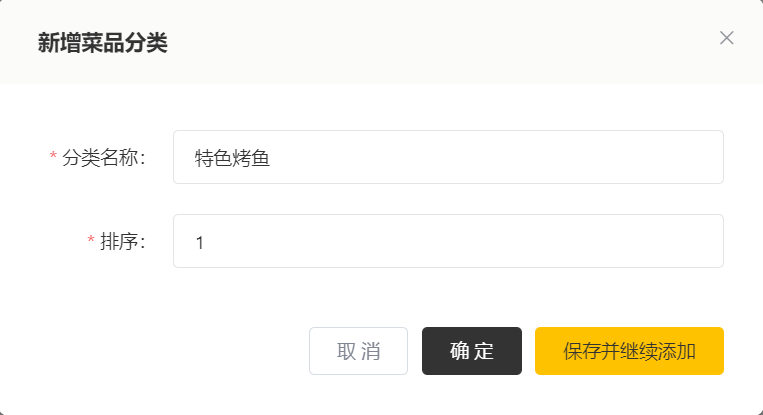 

**查看控制台**

通过观察控制台输出的SQL来确定公共字段填充是否完成

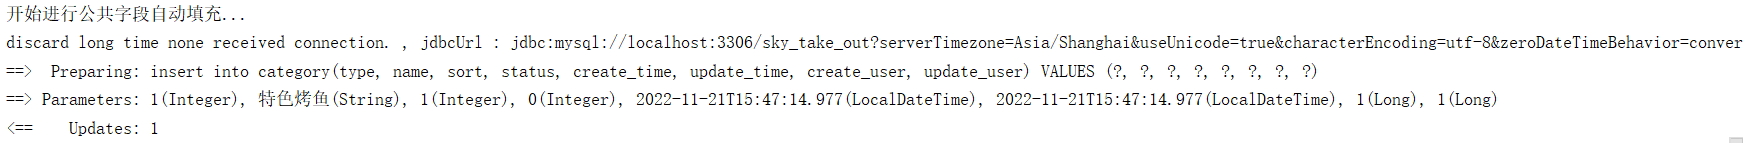

**查看表**

category表中数据

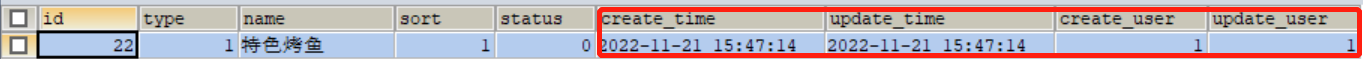

其中create_time,update_time,create_user,update_user字段都已完成自动填充。

由于使用admin(id=1)用户登录进行菜品添加操作,故create_user,update_user都为1.


### 公共字段验收（补充）

分别新增员工、分类并核对四项字段；再修改普通字段，确认仅更新时间和修改人变化。换一个已登录员工再修改，验证updateUser确实来自本次token。

断点应依次进入Controller、Service、AutoFillAspect和Mapper。出现“切面执行了但数据库没变”，检查SQL；出现“切面没执行”，检查注解位置、切入点、AOP依赖与Spring扫描。不要只看切面打印了一条日志就认定所有写入都已覆盖。


### 1.5 代码提交

**点击提交：**

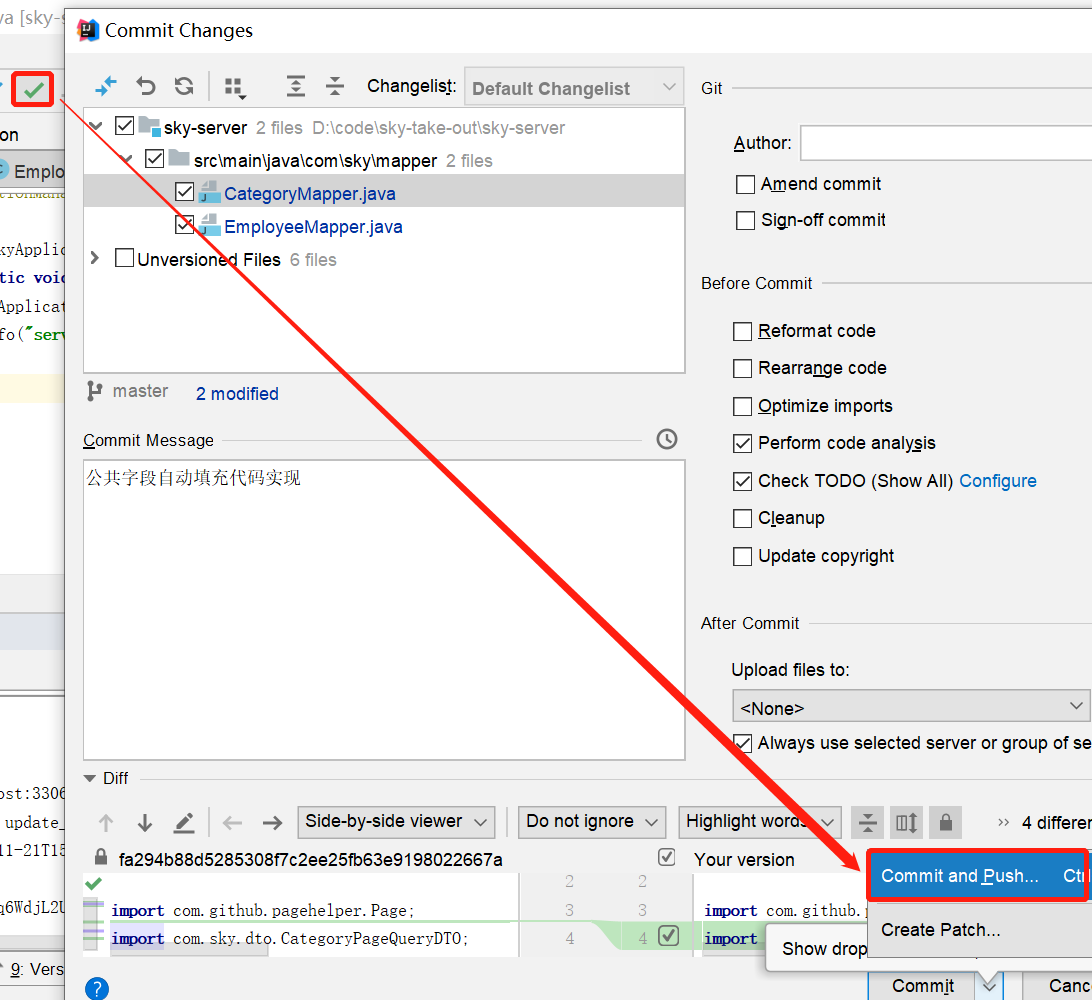 


**提交过程中**，出现提示：

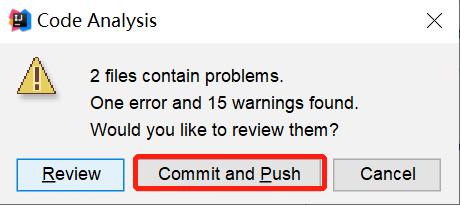 


**继续push:**

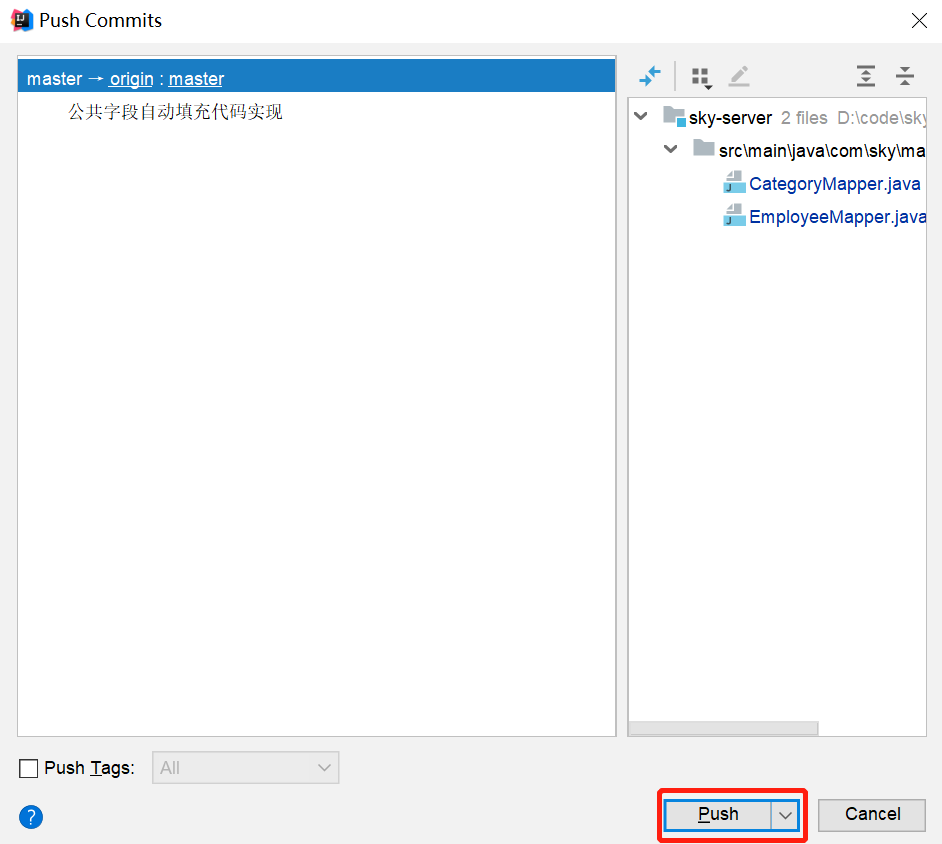 

**推送成功：**

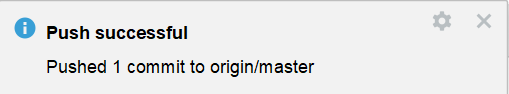


## 2. 新增菜品

> **PPT对照：** 第19—39页。


### 2.1 需求分析与设计

> **PPT对照：** 第20—26页。

#### 2.1.1 产品原型

后台系统中可以管理菜品信息，通过 **新增功能**来添加一个新的菜品，在添加菜品时需要选择当前菜品所属的菜品分类，并且需要上传菜品图片。

**新增菜品原型：**

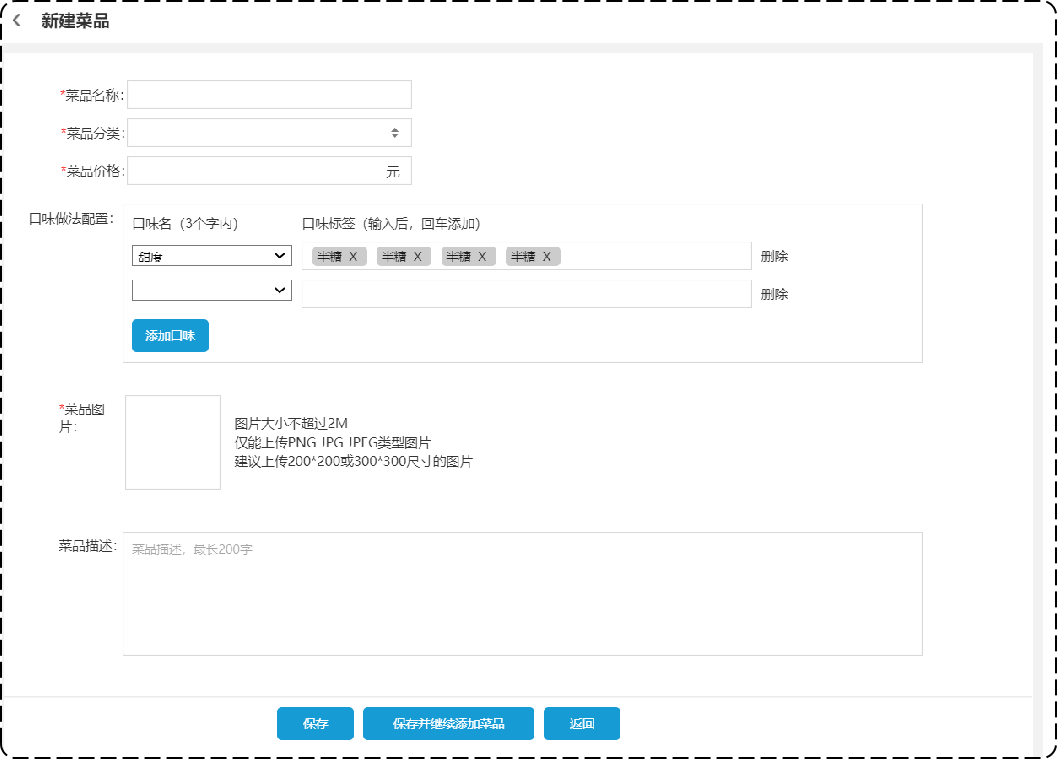 

当填写完表单信息, 点击"保存"按钮后, 会提交该表单的数据到服务端, 在服务端中需要接受数据, 然后将数据保存至数据库中。


**业务规则：**

- 菜品名称必须是唯一的
- 菜品必须属于某个分类下，不能单独存在
- 新增菜品时可以根据情况选择菜品的口味
- 每个菜品必须对应一张图片


#### 2.1.2 接口设计

根据上述原型图先**粗粒度**设计接口，共包含3个接口。

**接口设计：**

- 根据类型查询分类（已完成）
- 文件上传
- 新增菜品


接下来**细粒度**分析每个接口，明确每个接口的请求方式、请求路径、传入参数和返回值。

**1. 根据类型查询分类**

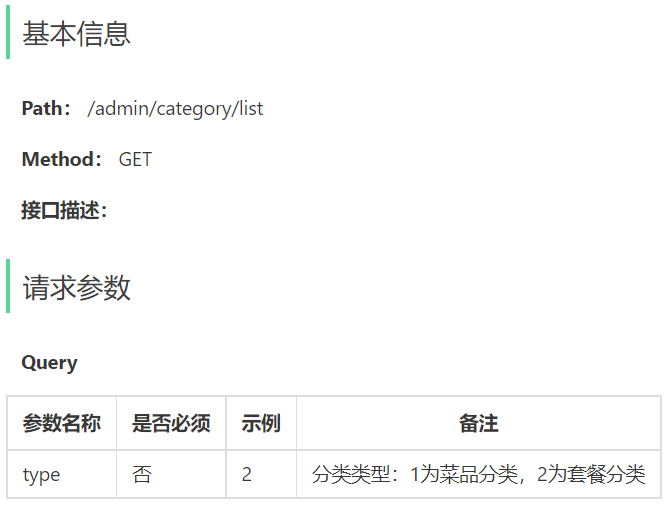 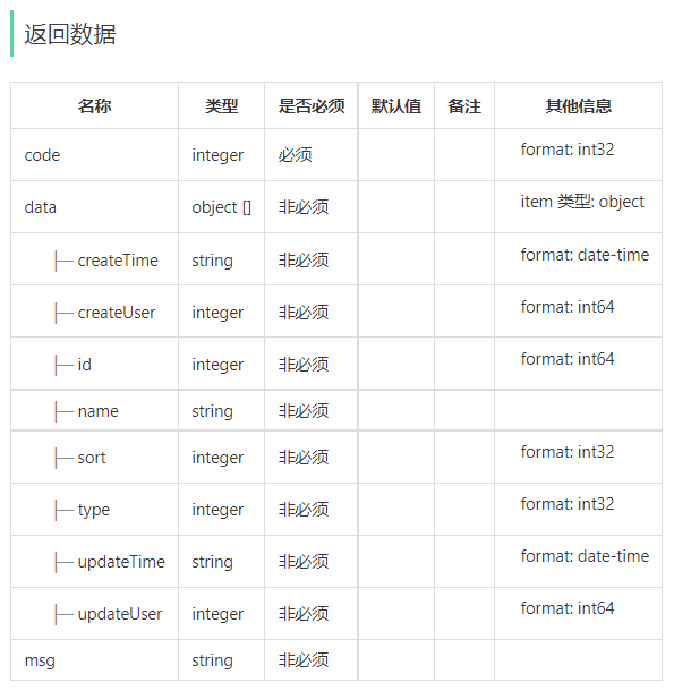

**2. 文件上传**

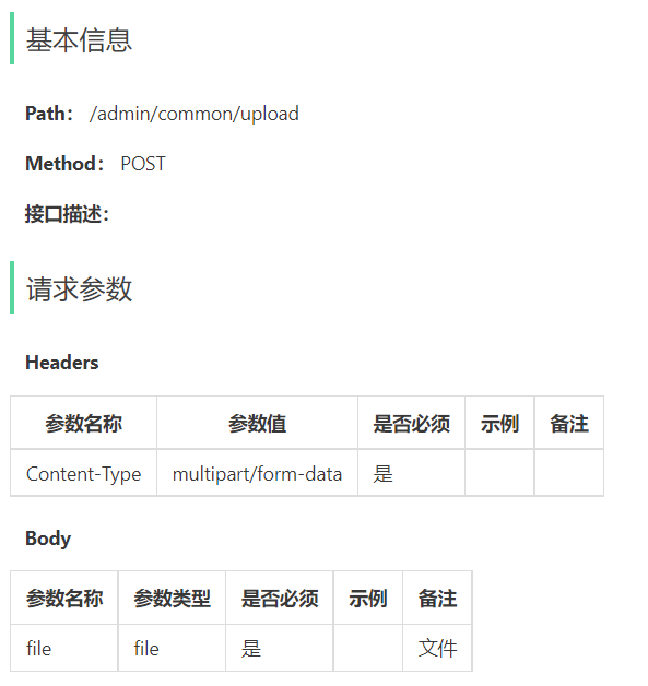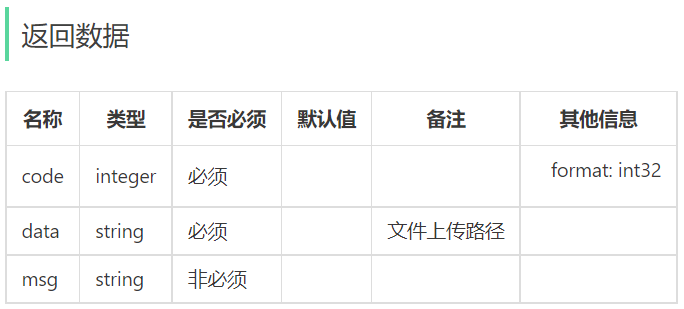


**3. 新增菜品**

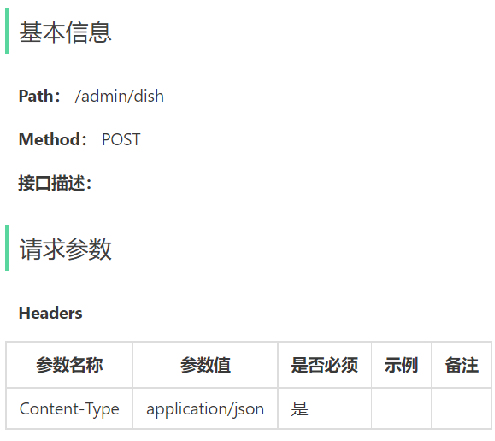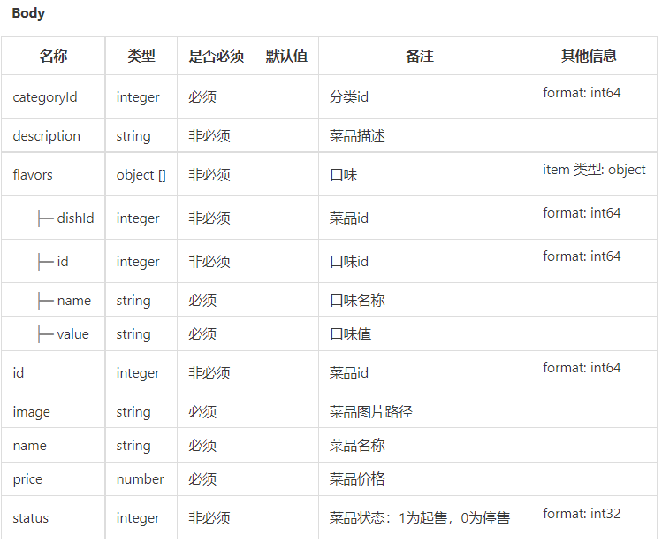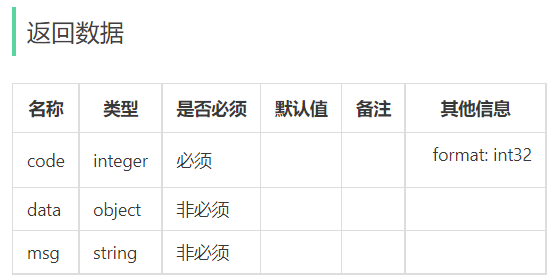


#### 2.1.3 表设计

通过原型图进行分析：

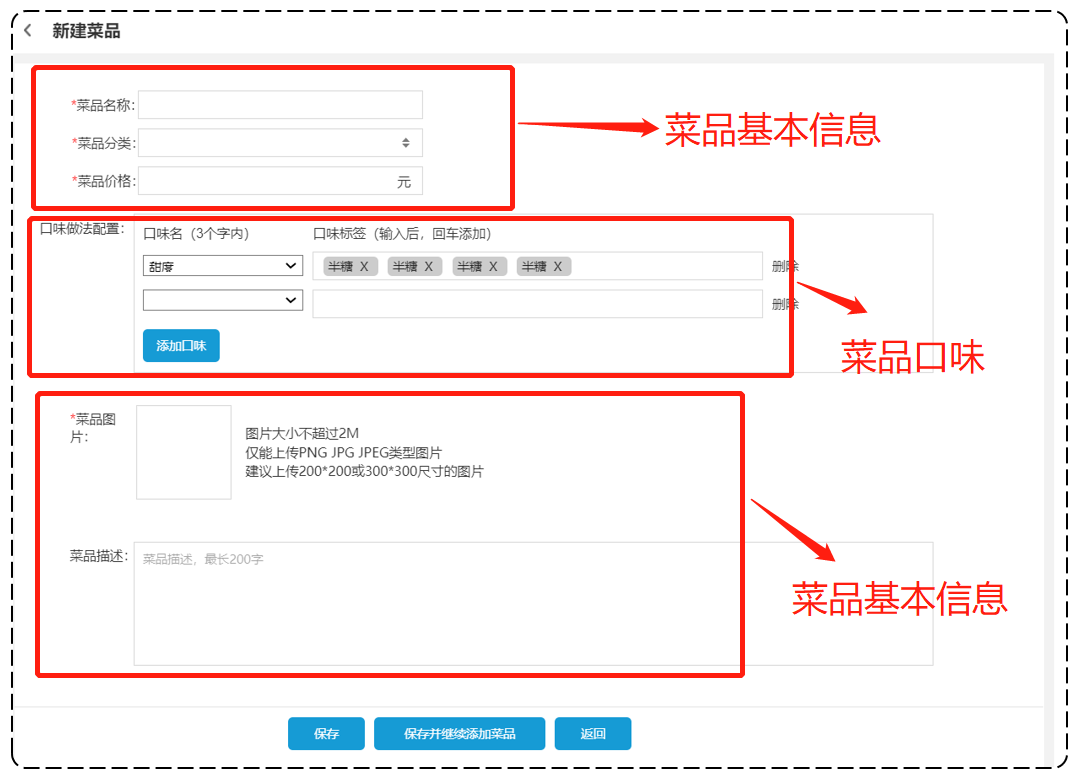 

新增菜品，其实就是将新增页面录入的菜品信息插入到dish表，如果添加了口味做法，还需要向dish_flavor表插入数据。所以在新增菜品时，涉及到两个表：

| 表名        | 说明       |
| ----------- | ---------- |
| dish        | 菜品表     |
| dish_flavor | 菜品口味表 |


**1). 菜品表:dish**

| **字段名**  | **数据类型**  | **说明**     | **备注**    |
| ----------- | ------------- | ------------ | ----------- |
| id          | bigint        | 主键         | 自增        |
| name        | varchar(32)   | 菜品名称     | 唯一        |
| category_id | bigint        | 分类id       | 逻辑外键    |
| price       | decimal(10,2) | 菜品价格     |             |
| image       | varchar(255)  | 图片路径     |             |
| description | varchar(255)  | 菜品描述     |             |
| status      | int           | 售卖状态     | 1起售 0停售 |
| create_time | datetime      | 创建时间     |             |
| update_time | datetime      | 最后修改时间 |             |
| create_user | bigint        | 创建人id     |             |
| update_user | bigint        | 最后修改人id |             |

**2). 菜品口味表:dish_flavor**

| **字段名** | **数据类型** | **说明** | **备注** |
| ---------- | ------------ | -------- | -------- |
| id         | bigint       | 主键     | 自增     |
| dish_id    | bigint       | 菜品id   | 逻辑外键 |
| name       | varchar(32)  | 口味名称 |          |
| value      | varchar(255) | 口味值   |          |


### 菜品与口味为什么拆成两张表（补充）

菜品基本信息是一条dish记录，口味是零到多条dish_flavor记录。把口味拆开，可以让一个菜品同时具有“辣度”“甜味”等独立选项；关联键是dish_flavor.dish_id。

`value`在课程前端与数据库示例中使用字符串形式的选项数组，例如 `["不辣","微辣","中辣"]`。Java属性是String，接口提交时它仍是一个字符串，不能直接改成JSON数组而不调整DTO、前端和持久化约定。

价格使用 `BigDecimal` 对应数据库 `decimal(10,2)`，不要用double进行金额计算。后端应校验名称非空且唯一、分类存在且type=1、价格范围和小数位、图片有效、status只允许0/1。下拉框只显示可用分类不等于后端已经校验分类可用性。

讲义规则要求图片必填，口味可选。新增状态由表单、接口约定与服务端规则共同确定，本章代码直接复制DTO的status，不要套用第二章“分类新增默认禁用”的规则来断言所有菜品默认停售。


### 2.2 代码开发

> **PPT对照：** 第28—37页。

#### 2.2.1 文件上传实现

因为在新增菜品时，需要上传菜品对应的图片(文件)，包括后绪其它功能也会使用到文件上传，故要实现通用的文件上传接口。

文件上传，是指将本地图片、视频、音频等文件上传到服务器上，可以供其他用户浏览或下载的过程。文件上传在项目中应用非常广泛，我们经常发抖音、发朋友圈都用到了文件上传功能。

实现文件上传服务，需要有存储的支持，那么我们的解决方案将以下几种：

1. 直接将图片保存到服务的硬盘（springmvc中的文件上传）
   1. 优点：开发便捷，成本低
   2. 缺点：扩容困难
2. 使用分布式文件系统进行存储
   1. 优点：容易实现扩容
   2. 缺点：开发复杂度稍大（有成熟的产品可以使用，比如：FastDFS,MinIO）
3. 使用第三方的存储服务（例如OSS）
   1. 优点：开发简单，拥有强大功能，免维护
   2. 缺点：付费

在本项目选用阿里云的OSS服务进行文件存储。（前面课程已学习过阿里云OSS,不再赘述）

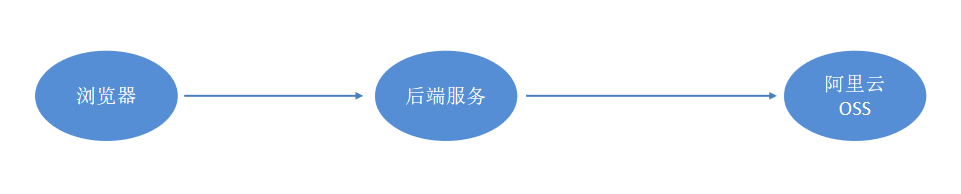 

**实现步骤：**

**1). 定义OSS相关配置**

在sky-server模块

application-dev.yml

```yaml
sky:
  alioss:
    endpoint: oss-cn-hangzhou.aliyuncs.com
    access-key-id: <填写你的AccessKeyId>
    access-key-secret: <填写你的AccessKeySecret>
    bucket-name: sky-take-out
```

application.yml

```yaml
spring:
  profiles:
    active: dev    #设置环境
sky:
  alioss:
    endpoint: ${sky.alioss.endpoint}
    access-key-id: ${sky.alioss.access-key-id}
    access-key-secret: ${sky.alioss.access-key-secret}
    bucket-name: ${sky.alioss.bucket-name}

```


**2). 读取OSS配置**

在sky-common模块中，已定义

```java
package com.sky.properties;

import lombok.Data;
import org.springframework.boot.context.properties.ConfigurationProperties;
import org.springframework.stereotype.Component;

@Component
@ConfigurationProperties(prefix = "sky.alioss")
@Data
public class AliOssProperties {

    private String endpoint;
    private String accessKeyId;
    private String accessKeySecret;
    private String bucketName;

}
```


**3). 生成OSS工具类对象**

在sky-server模块

```java
package com.sky.config;

import com.sky.properties.AliOssProperties;
import com.sky.utils.AliOssUtil;
import lombok.extern.slf4j.Slf4j;
import org.springframework.boot.autoconfigure.condition.ConditionalOnMissingBean;
import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;

/**
 * 配置类，用于创建AliOssUtil对象
 */
@Configuration
@Slf4j
public class OssConfiguration {

    @Bean
    @ConditionalOnMissingBean
    public AliOssUtil aliOssUtil(AliOssProperties aliOssProperties){
        log.info("开始创建阿里云文件上传工具类对象：{}",aliOssProperties);
        return new AliOssUtil(aliOssProperties.getEndpoint(),
                aliOssProperties.getAccessKeyId(),
                aliOssProperties.getAccessKeySecret(),
                aliOssProperties.getBucketName());
    }
}
```

其中，AliOssUtil.java已在sky-common模块中定义

```java
package com.sky.utils;

import com.aliyun.oss.ClientException;
import com.aliyun.oss.OSS;
import com.aliyun.oss.OSSClientBuilder;
import com.aliyun.oss.OSSException;
import lombok.AllArgsConstructor;
import lombok.Data;
import lombok.extern.slf4j.Slf4j;
import java.io.ByteArrayInputStream;

@Data
@AllArgsConstructor
@Slf4j
public class AliOssUtil {

    private String endpoint;
    private String accessKeyId;
    private String accessKeySecret;
    private String bucketName;

    /**
     * 文件上传
     *
     * @param bytes
     * @param objectName
     * @return
     */
    public String upload(byte[] bytes, String objectName) {

        // 创建OSSClient实例。
        OSS ossClient = new OSSClientBuilder().build(endpoint, accessKeyId, accessKeySecret);

        try {
            // 创建PutObject请求。
            ossClient.putObject(bucketName, objectName, new ByteArrayInputStream(bytes));
        } catch (OSSException oe) {
            System.out.println("Caught an OSSException, which means your request made it to OSS, "
                    + "but was rejected with an error response for some reason.");
            System.out.println("Error Message:" + oe.getErrorMessage());
            System.out.println("Error Code:" + oe.getErrorCode());
            System.out.println("Request ID:" + oe.getRequestId());
            System.out.println("Host ID:" + oe.getHostId());
        } catch (ClientException ce) {
            System.out.println("Caught an ClientException, which means the client encountered "
                    + "a serious internal problem while trying to communicate with OSS, "
                    + "such as not being able to access the network.");
            System.out.println("Error Message:" + ce.getMessage());
        } finally {
            if (ossClient != null) {
                ossClient.shutdown();
            }
        }

        //文件访问路径规则 https://BucketName.Endpoint/ObjectName
        StringBuilder stringBuilder = new StringBuilder("https://");
        stringBuilder
                .append(bucketName)
                .append(".")
                .append(endpoint)
                .append("/")
                .append(objectName);

        log.info("文件上传到:{}", stringBuilder.toString());

        return stringBuilder.toString();
    }
}
```


**4). 定义文件上传接口**

在sky-server模块中定义接口

```java
package com.sky.controller.admin;

import com.sky.constant.MessageConstant;
import com.sky.result.Result;
import com.sky.utils.AliOssUtil;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import org.springframework.web.multipart.MultipartFile;
import java.io.IOException;
import java.util.UUID;

/**
 * 通用接口
 */
@RestController
@RequestMapping("/admin/common")
@Api(tags = "通用接口")
@Slf4j
public class CommonController {

    @Autowired
    private AliOssUtil aliOssUtil;

    /**
     * 文件上传
     * @param file
     * @return
     */
    @PostMapping("/upload")
    @ApiOperation("文件上传")
    public Result<String> upload(MultipartFile file){
        log.info("文件上传：{}",file);

        try {
            //原始文件名
            String originalFilename = file.getOriginalFilename();
            //截取原始文件名的后缀   dfdfdf.png
            String extension = originalFilename.substring(originalFilename.lastIndexOf("."));
            //构造新文件名称
            String objectName = UUID.randomUUID().toString() + extension;

            //文件的请求路径
            String filePath = aliOssUtil.upload(file.getBytes(), objectName);
            return Result.success(filePath);
        } catch (IOException e) {
            log.error("文件上传失败：{}", e);
        }

        return Result.error(MessageConstant.UPLOAD_FAILED);
    }
}
```


#### 2.2.2 新增菜品实现

**1). 设计DTO类**

在sky-pojo模块中

```java
package com.sky.dto;

import com.sky.entity.DishFlavor;
import lombok.Data;
import java.io.Serializable;
import java.math.BigDecimal;
import java.util.ArrayList;
import java.util.List;

@Data
public class DishDTO implements Serializable {

    private Long id;
    //菜品名称
    private String name;
    //菜品分类id
    private Long categoryId;
    //菜品价格
    private BigDecimal price;
    //图片
    private String image;
    //描述信息
    private String description;
    //0 停售 1 起售
    private Integer status;
    //口味
    private List<DishFlavor> flavors = new ArrayList<>();
}
```


**2). Controller层**

进入到sky-server模块

```java
package com.sky.controller.admin;

import com.sky.dto.DishDTO;
import com.sky.dto.DishPageQueryDTO;
import com.sky.entity.Dish;
import com.sky.result.PageResult;
import com.sky.result.Result;
import com.sky.service.DishService;
import com.sky.vo.DishVO;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.*;
import java.util.List;
import java.util.Set;

/**
 * 菜品管理
 */
@RestController
@RequestMapping("/admin/dish")
@Api(tags = "菜品相关接口")
@Slf4j
public class DishController {

    @Autowired
    private DishService dishService;

    /**
     * 新增菜品
     *
     * @param dishDTO
     * @return
     */
    @PostMapping
    @ApiOperation("新增菜品")
    public Result save(@RequestBody DishDTO dishDTO) {
        log.info("新增菜品：{}", dishDTO);
        dishService.saveWithFlavor(dishDTO);//后绪步骤开发
        return Result.success();
    }
}
```


**3). Service层接口**

```java
package com.sky.service;

import com.sky.dto.DishDTO;
import com.sky.entity.Dish;

public interface DishService {

    /**
     * 新增菜品和对应的口味
     *
     * @param dishDTO
     */
    public void saveWithFlavor(DishDTO dishDTO);

}
```


**4). Service层实现类**

```java
package com.sky.service.impl;


@Service
@Slf4j
public class DishServiceImpl implements DishService {

    @Autowired
    private DishMapper dishMapper;
    @Autowired
    private DishFlavorMapper dishFlavorMapper;

    /**
     * 新增菜品和对应的口味
     *
     * @param dishDTO
     */
    @Transactional
    public void saveWithFlavor(DishDTO dishDTO) {

        Dish dish = new Dish();
        BeanUtils.copyProperties(dishDTO, dish);

        //向菜品表插入1条数据
        dishMapper.insert(dish);//后绪步骤实现

        //获取insert语句生成的主键值
        Long dishId = dish.getId();

        List<DishFlavor> flavors = dishDTO.getFlavors();
        if (flavors != null && flavors.size() > 0) {
            flavors.forEach(dishFlavor -> {
                dishFlavor.setDishId(dishId);
            });
            //向口味表插入n条数据
            dishFlavorMapper.insertBatch(flavors);//后绪步骤实现
        }
    }

}
```


**5). Mapper层**

DishMapper.java中添加

```java
	/**
     * 插入菜品数据
     *
     * @param dish
     */
    @AutoFill(value = OperationType.INSERT)
    void insert(Dish dish);
```

在/resources/mapper中创建DishMapper.xml

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.DishMapper">

    <insert id="insert" useGeneratedKeys="true" keyProperty="id">
        insert into dish (name, category_id, price, image, description, create_time, update_time, create_user,update_user, status)
        values (#{name}, #{categoryId}, #{price}, #{image}, #{description}, #{createTime}, #{updateTime}, #{createUser}, #{updateUser}, #{status})
    </insert>
</mapper>

```

DishFlavorMapper.java

```java
package com.sky.mapper;

import com.sky.entity.DishFlavor;
import java.util.List;

@Mapper
public interface DishFlavorMapper {
    /**
     * 批量插入口味数据
     * @param flavors
     */
    void insertBatch(List<DishFlavor> flavors);

}
```

在/resources/mapper中创建DishFlavorMapper.xml

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.DishFlavorMapper">
    <insert id="insertBatch">
        insert into dish_flavor (dish_id, name, value) VALUES
        <foreach collection="flavors" item="df" separator=",">
            (#{df.dishId},#{df.name},#{df.value})
        </foreach>
    </insert>
</mapper>
```


### 图片上传与新增菜品的实现串联（补充与勘误）

#### 1. OSS配置先核对地域和绑定

讲义示例使用杭州Endpoint与sky-take-out，PPT示例使用北京Endpoint与sky-itcast。两者是不同演示环境，跟练时必须填自己的Bucket与对应地域，不能交叉复制。

`@ConfigurationProperties(prefix="sky.alioss")`把配置绑定到AliOssProperties，OssConfiguration再用这些值创建AliOssUtil。`@ConditionalOnMissingBean`表示容器没有同类型Bean时才注册，便于替换实现。

原主配置使用同名占位符，由激活的dev配置提供具体值；如果只保留这些自引用而删掉dev中的具体值，可能无法解析或产生循环引用。下面给出独立的环境变量配置方案，可放入实际启用的配置文件，避免两套同名定义互相覆盖：

```yaml
sky:
  alioss:
    endpoint: ${OSS_ENDPOINT}
    access-key-id: ${OSS_ACCESS_KEY_ID}
    access-key-secret: ${OSS_ACCESS_KEY_SECRET}
    bucket-name: ${OSS_BUCKET_NAME}
```

运行前在本地启动环境设置四个变量；不要把真实凭据写进笔记或提交到仓库。原OssConfiguration日志输出整个AliOssProperties，而 `@Data`生成的toString包含密钥字段。可只记录非敏感的Bucket和Endpoint：

```java
log.info("创建OSS上传工具，bucket={}，endpoint={}",
        aliOssProperties.getBucketName(), aliOssProperties.getEndpoint());
```

#### 2. OSS上传失败不能返回成功URL

原AliOssUtil捕获OSSException和ClientException后没有终止，继续拼接URL返回。Controller就可能生成 `Result.success(filePath)`，但对象实际未上传。可将工具类中的upload方法替换为：

```java
// 放在已有AliOssUtil类中；沿用原字段与OSS SDK imports。
public String upload(byte[] bytes, String objectName) {
    OSS ossClient = new OSSClientBuilder()
            .build(endpoint, accessKeyId, accessKeySecret);
    try {
        ossClient.putObject(bucketName, objectName,
                new ByteArrayInputStream(bytes));
        // 仅在putObject成功后返回。这里沿用无协议前缀的Endpoint配置。
        return "https://" + bucketName + "." + endpoint + "/" + objectName;
    } catch (OSSException | ClientException e) {
        throw new IllegalStateException("OSS文件上传失败", e);
    } finally {
        ossClient.shutdown();
    }
}
```

Controller同步处理该异常，或交给现有全局异常处理器。若采用Controller处理，将原IOException分支改为：

```java
catch (IOException | IllegalStateException e) {
    log.error("文件上传失败", e);
    return Result.error(MessageConstant.UPLOAD_FAILED);
}
```

异常日志按环境控制内容，响应只给简明错误。这个修正针对原工具类吞掉上传失败的问题；文件名和文件格式仍需在调用之前校验。

#### 3. MultipartFile不是JSON字段

推荐显式写出上传字段名：

```java
public Result<String> upload(@RequestParam("file") MultipartFile file) {
    // 校验文件、生成对象名、调用上传工具，沿用前述流程。
}
```

补充 `org.springframework.web.bind.annotation.RequestParam` import。请求Content-Type为multipart/form-data，字段名为file，不能把文件路径当作JSON字符串提交。接口工具或浏览器负责生成boundary。

原 `substring(lastIndexOf("."))` 对null或没有后缀的文件名不安全。上传前检查空文件、文件名、后缀白名单、实际内容类型与大小，统一大小写后再生成UUID对象名。后缀与客户端Content-Type都可伪造，不能只检查字符串就认定是图片。UUID减少名称冲突，不表示文件已经过内容校验。

大文件报413时同时检查Nginx的请求体上限和Spring的multipart配置；参数名错误可能导致file为空。示例限制可按课程图片大小调整：

```yaml
spring:
  servlet:
    multipart:
      max-file-size: 5MB
      max-request-size: 6MB
```

工具类拼出的URL能否直接打开，还取决于Bucket读取权限或访问域名。私有对象通常需要签名URL，临时签名URL会过期；长期数据可存对象key，展示时生成可用地址，按实际访问方案设计。不要为修复403随意开放整个Bucket写权限。

#### 4. 先回填菜品主键，再关联口味

```text
BeanUtils复制基本信息 → dishMapper.insert(dish)
    → useGeneratedKeys=true、keyProperty=id将主键写回dish.id
    → 对所有flavor设置dishId=dish.id
    → insertBatch一次插入多条口味
```

BeanUtils是浅拷贝：它不会帮你把flavors插进数据库，也不会自动建立外键关联。新增时应忽略客户端传来的菜品id和口味关联id，主键由数据库生成，dishId由服务端设置。

原插入SQL不写口味id，所以该id仍由数据库生成。空口味集合可跳过insertBatch；不能对空列表直接生成只有 `VALUES` 的SQL。明确MyBatis集合参数名能减少对编译参数名配置的依赖：

```java
void insertBatch(@org.apache.ibatis.annotations.Param("flavors")
                 List<DishFlavor> flavors);
```

XML继续用 `collection="flavors"`。原 `@Transactional` 将dish和dish_flavor的数据库写入组成一个整体；中间抛出运行时异常应全部回滚，不能catch后只打印再返回成功。事务需要从Spring代理调用，且表与事务管理器必须支持这组数据库操作。

OSS上传不参加此数据库事务。图片先上传成功、菜品保存失败时可能产生孤立对象；实际项目可用临时对象、失败补偿或定期清理机制处理，不能认为数据库回滚会自动删除OSS图片。


### 2.3 功能测试

> **PPT对照：** 第39页。

进入到菜品管理--->新建菜品

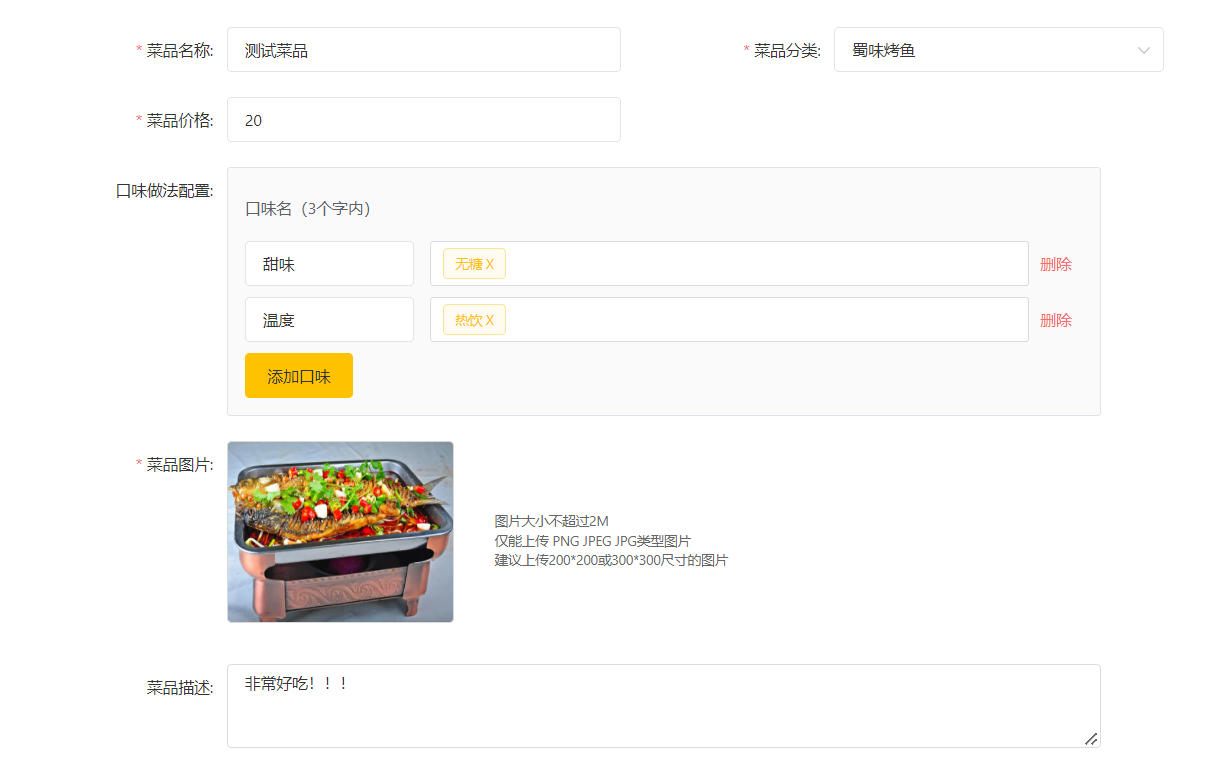 

由于没有实现菜品查询功能，所以保存后，暂且在表中查看添加的数据。

dish表：

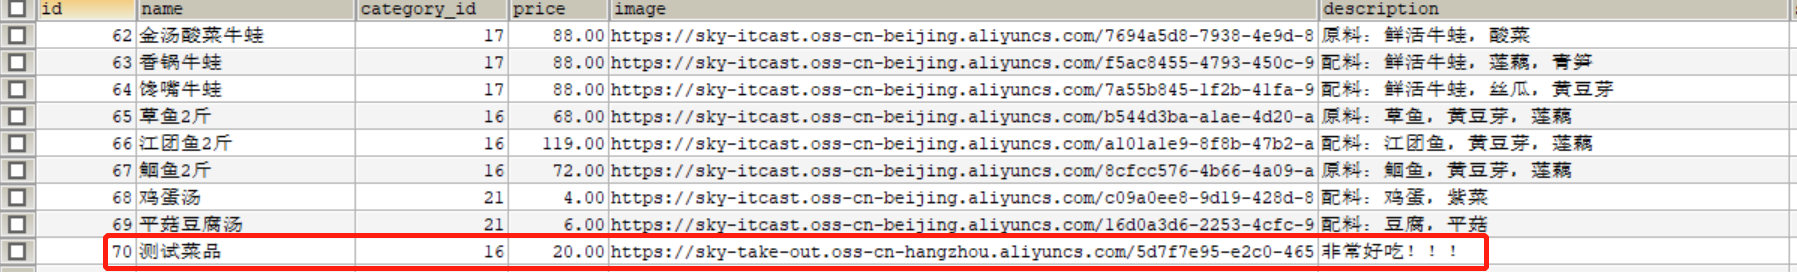 

dish_flavor表：

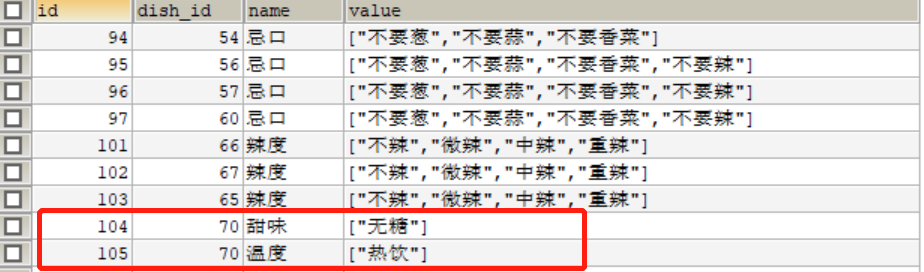 

测试成功。


### 新增与上传验收（补充）

| 测试 | 核对结果 |
| --- | --- |
| 上传正常图片 | 返回可用地址，OSS确实有该对象 |
| 错误凭据或不可用网络 | 返回失败，不给虚假的成功URL |
| 空文件、无后缀、非图片、超大文件 | 按接口规则拒绝，有明确提示 |
| 新增带两条口味的菜品 | dish一条、dish_flavor两条，dish_id一致 |
| 新增不带口味的菜品 | dish保存成功，没有空集合批量SQL |
| 重复菜品名称 | 唯一约束与统一异常处理产生业务错误 |
| 不存在或类型不匹配的分类 | 后端拒绝无效关联 |
| 口味写入中途失败 | dish和所有本次口味一起回滚 |

在测试库使用故意超出数据库列限制等可控方式触发插入失败，检查事务效果；不要在真实业务数据上制造错误。本阶段分页尚未完成时，先按新增菜品id核对两张表，页面暂时没有列表不等于保存失败。


### 2.4代码提交

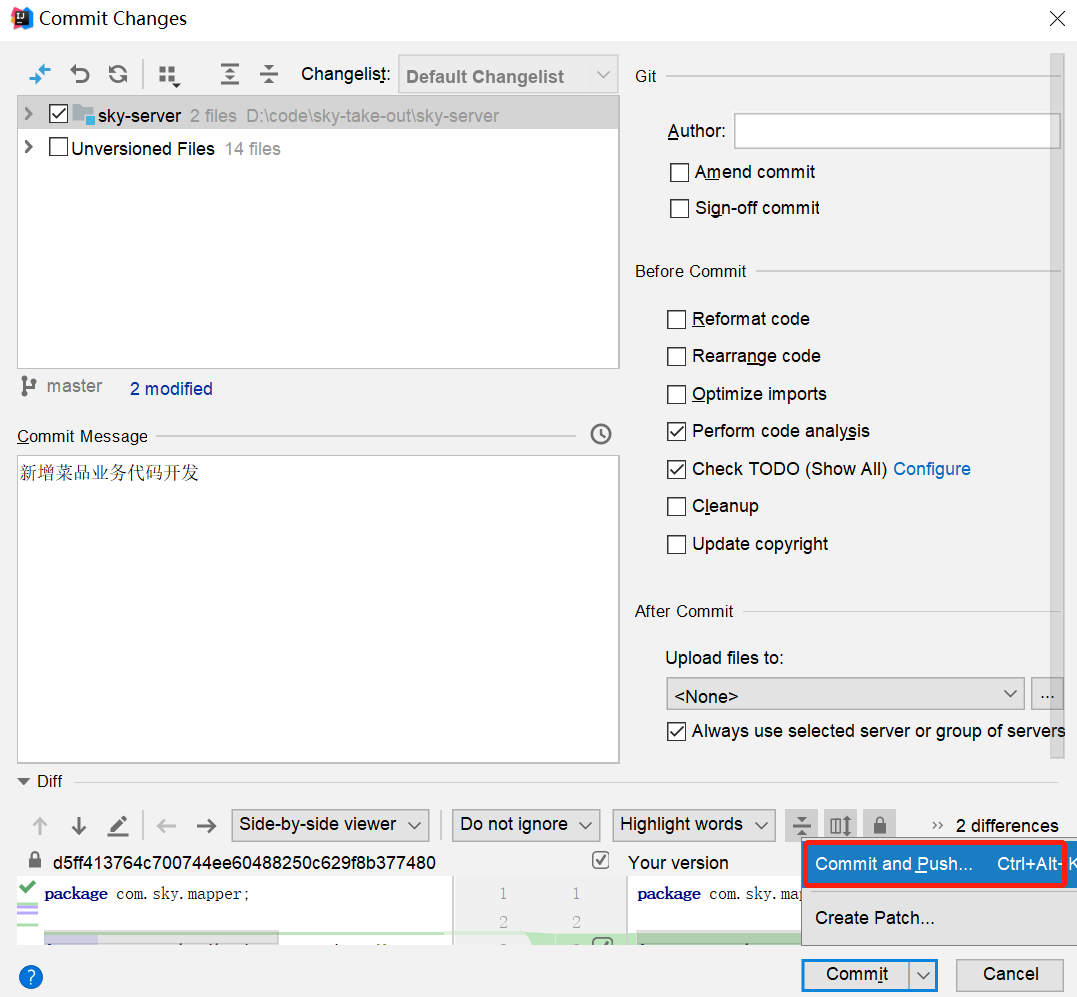  

后续步骤和上述功能代码提交一致，不再赘述。


## 3. 菜品分页查询

> **PPT对照：** 第41—54页。


### 3.1 需求分析和设计

> **PPT对照：** 第42—44页。

#### 3.1.1 产品原型

系统中的菜品数据很多的时候，如果在一个页面中全部展示出来会显得比较乱，不便于查看，所以一般的系统中都会以分页的方式来展示列表数据。

**菜品分页原型：**

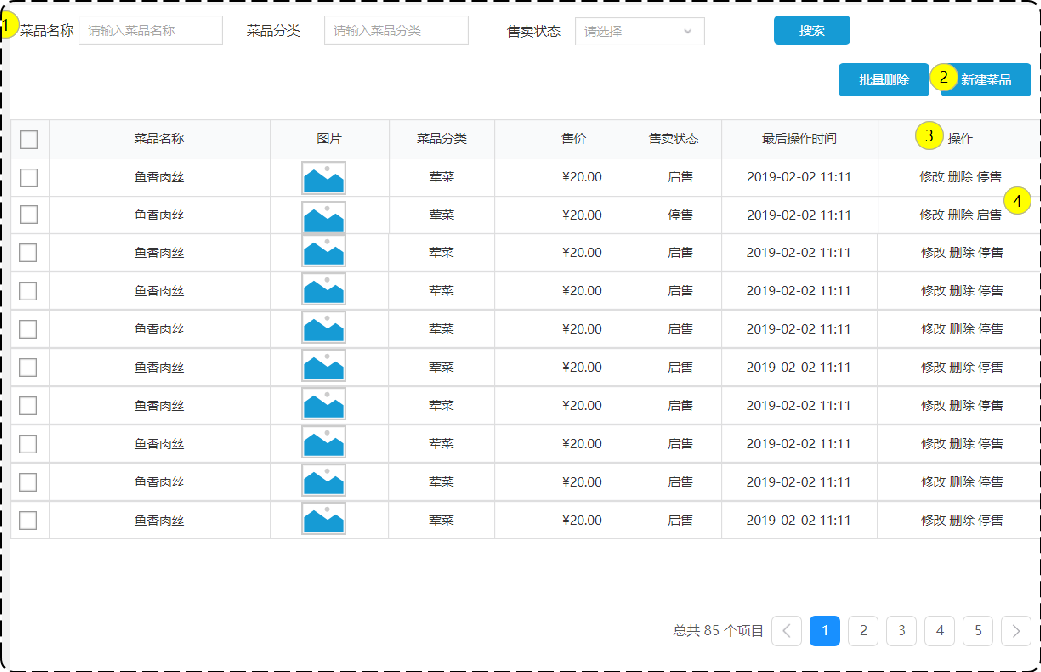 

在菜品列表展示时，除了菜品的基本信息(名称、售价、售卖状态、最后操作时间)外，还有两个字段略微特殊，第一个是图片字段 ，我们从数据库查询出来的仅仅是图片的名字，图片要想在表格中回显展示出来，就需要下载这个图片。第二个是菜品分类，这里展示的是分类名称，而不是分类ID，此时我们就需要根据菜品的分类ID，去分类表中查询分类信息，然后在页面展示。

**业务规则：**

- 根据页码展示菜品信息
- 每页展示10条数据
- 分页查询时可以根据需要输入菜品名称、菜品分类、菜品状态进行查询


#### 3.1.2 接口设计

根据上述原型图，设计出相应的接口。

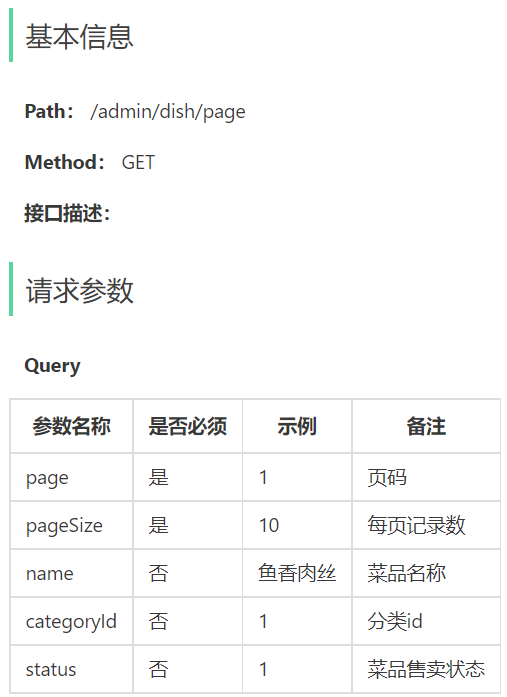 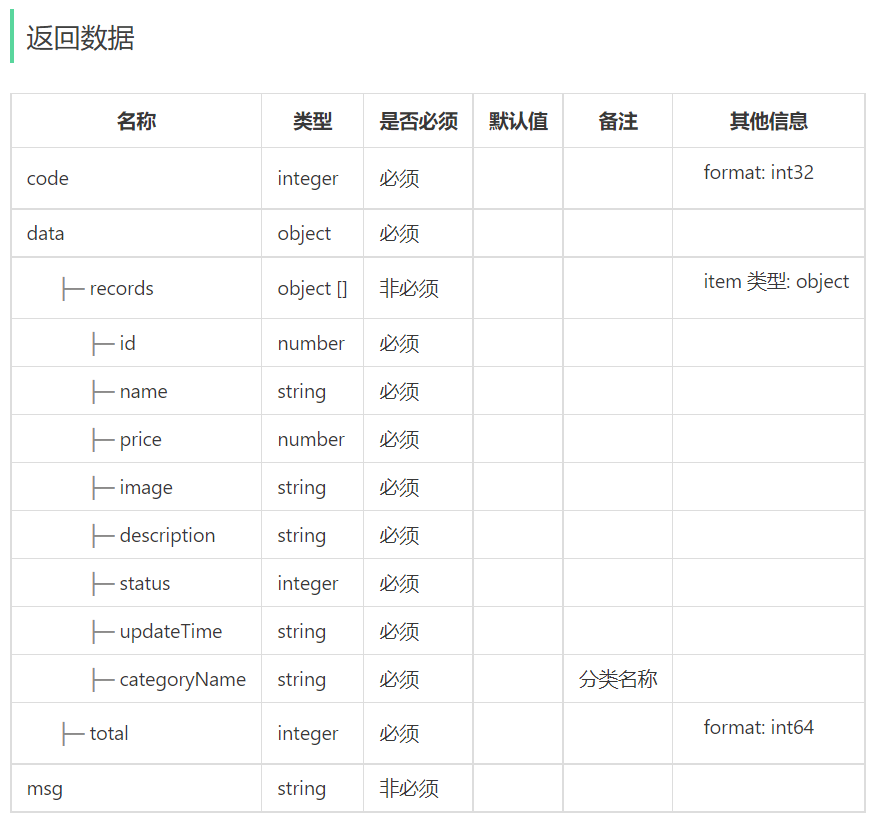


### 分页列表展示字段的来源（补充与勘误）

| 列表内容 | 来源 |
| --- | --- |
| 名称、价格、状态、更新时间 | dish表 |
| 分类名称categoryName | 关联category表的name |
| 图片 | dish.image提供地址，浏览器再请求图片资源 |
| 口味 | 本章分页SQL未查询；编辑回显单独查询 |

原文说数据库只存“图片的名字”，但前面上传接口返回并保存的是URL。按原实现跟练应把image当作完整URL；若改为存对象key，前后端要统一构造访问地址，避免重复拼接域名。

菜品分页按名称、分类、状态组合过滤。page/pageSize来自Query参数；本章页面每页10条是页面设计，Service仍需校验实际传入的分页范围。status=0表示停售，是有效过滤条件，不能当作“没有传”。


### 3.2 代码开发

> **PPT对照：** 第46—52页。

#### 3.2.1 设计DTO类

**根据菜品分页查询接口定义设计对应的DTO：**

在sky-pojo模块中，已定义

```java
package com.sky.dto;

import lombok.Data;
import java.io.Serializable;

@Data
public class DishPageQueryDTO implements Serializable {

    private int page;
    private int pageSize;
    private String name;
    private Integer categoryId; //分类id
    private Integer status; //状态 0表示禁用 1表示启用

}
```


#### 3.2.2 设计VO类

**根据菜品分页查询接口定义设计对应的VO：**

在sky-pojo模块中，已定义

```java
package com.sky.vo;

import com.sky.entity.DishFlavor;
import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.io.Serializable;
import java.math.BigDecimal;
import java.time.LocalDateTime;
import java.util.ArrayList;
import java.util.List;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
public class DishVO implements Serializable {

    private Long id;
    //菜品名称
    private String name;
    //菜品分类id
    private Long categoryId;
    //菜品价格
    private BigDecimal price;
    //图片
    private String image;
    //描述信息
    private String description;
    //0 停售 1 起售
    private Integer status;
    //更新时间
    private LocalDateTime updateTime;
    //分类名称
    private String categoryName;
    //菜品关联的口味
    private List<DishFlavor> flavors = new ArrayList<>();
}
```


#### 3.2.3 Controller层

**根据接口定义创建DishController的page分页查询方法：**

```java
	/**
     * 菜品分页查询
     *
     * @param dishPageQueryDTO
     * @return
     */
    @GetMapping("/page")
    @ApiOperation("菜品分页查询")
    public Result<PageResult> page(DishPageQueryDTO dishPageQueryDTO) {
        log.info("菜品分页查询:{}", dishPageQueryDTO);
        PageResult pageResult = dishService.pageQuery(dishPageQueryDTO);//后绪步骤定义
        return Result.success(pageResult);
    }
```


#### 3.2.4 Service层接口

**在 DishService 中扩展分页查询方法：**

```java
	/**
     * 菜品分页查询
     *
     * @param dishPageQueryDTO
     * @return
     */
    PageResult pageQuery(DishPageQueryDTO dishPageQueryDTO);
```


#### 3.2.5 Service层实现类

**在 DishServiceImpl 中实现分页查询方法：**

```java
	/**
     * 菜品分页查询
     *
     * @param dishPageQueryDTO
     * @return
     */
    public PageResult pageQuery(DishPageQueryDTO dishPageQueryDTO) {
        PageHelper.startPage(dishPageQueryDTO.getPage(), dishPageQueryDTO.getPageSize());
        Page<DishVO> page = dishMapper.pageQuery(dishPageQueryDTO);//后绪步骤实现
        return new PageResult(page.getTotal(), page.getResult());
    }
```


#### 3.2.6 Mapper层

**在 DishMapper 接口中声明 pageQuery 方法：**

```java
	/**
     * 菜品分页查询
     *
     * @param dishPageQueryDTO
     * @return
     */
    Page<DishVO> pageQuery(DishPageQueryDTO dishPageQueryDTO);
```

**在 DishMapper.xml 中编写SQL：**

```xml
<select id="pageQuery" resultType="com.sky.vo.DishVO">
        select d.* , c.name as categoryName from dish d left outer join category c on d.category_id = c.id
        <where>
            <if test="name != null">
                and d.name like concat('%',#{name},'%')
            </if>
            <if test="categoryId != null">
                and d.category_id = #{categoryId}
            </if>
            <if test="status != null">
                and d.status = #{status}
            </if>
        </where>
        order by d.create_time desc
</select>
```


### PageHelper、LEFT JOIN与DTO类型（补充与勘误）

原DishPageQueryDTO.categoryId是Integer，而数据库分类主键是bigint、DishDTO和DishVO使用Long。建议统一为 `Long categoryId`，避免大id超出范围；这是明确的类型修正，原代码保留便于对照。

SQL使用LEFT OUTER JOIN，即使分类记录缺失仍会返回菜品，只是categoryName为null。LEFT JOIN能维持列表结果，不会修复无效分类关联；新增与修改时仍应检查分类。

`c.name as categoryName`对齐VO属性，`d.*`提供菜品字段。分页没有关联dish_flavor，所以不能因为DishVO定义了flavors就以为口味已经查询：默认空集合只表示未填充或无数据，要结合接口用途判断。

PageHelper.startPage紧接本次Mapper分页查询，不在中间插入分类查询等其他查询；返回total是符合条件的总条数，records只是当前页。

可保留原联表主体，将条件与排序写得更明确：

```xml
<where>
    <if test="name != null and name != ''">
        and d.name like concat('%', #{name}, '%')
    </if>
    <if test="categoryId != null">
        and d.category_id = #{categoryId}
    </if>
    <if test="status != null">
        and d.status = #{status}
    </if>
</where>
order by d.create_time desc, d.id desc
```

这是原select内where与order by的替换示例。name可先在Service trim；用 `#{...}`绑定参数，不将用户输入直接拼成SQL。第二排序键有助于相同创建时间下保持顺序；分页期间发生新增删除时仍需接受偏移分页的变化。

更新时间JSON格式复用第二章已经配置的消息转换器，不要为菜品分页再注册一套不一致的ObjectMapper。


### 3.3 功能测试

> **PPT对照：** 第54页。

#### 3.3.1 接口文档测试

**启动服务：**访问http://localhost:8080/doc.html，进入菜品分页查询接口

**注意：**使用admin用户登录重新获取token，防止token失效。

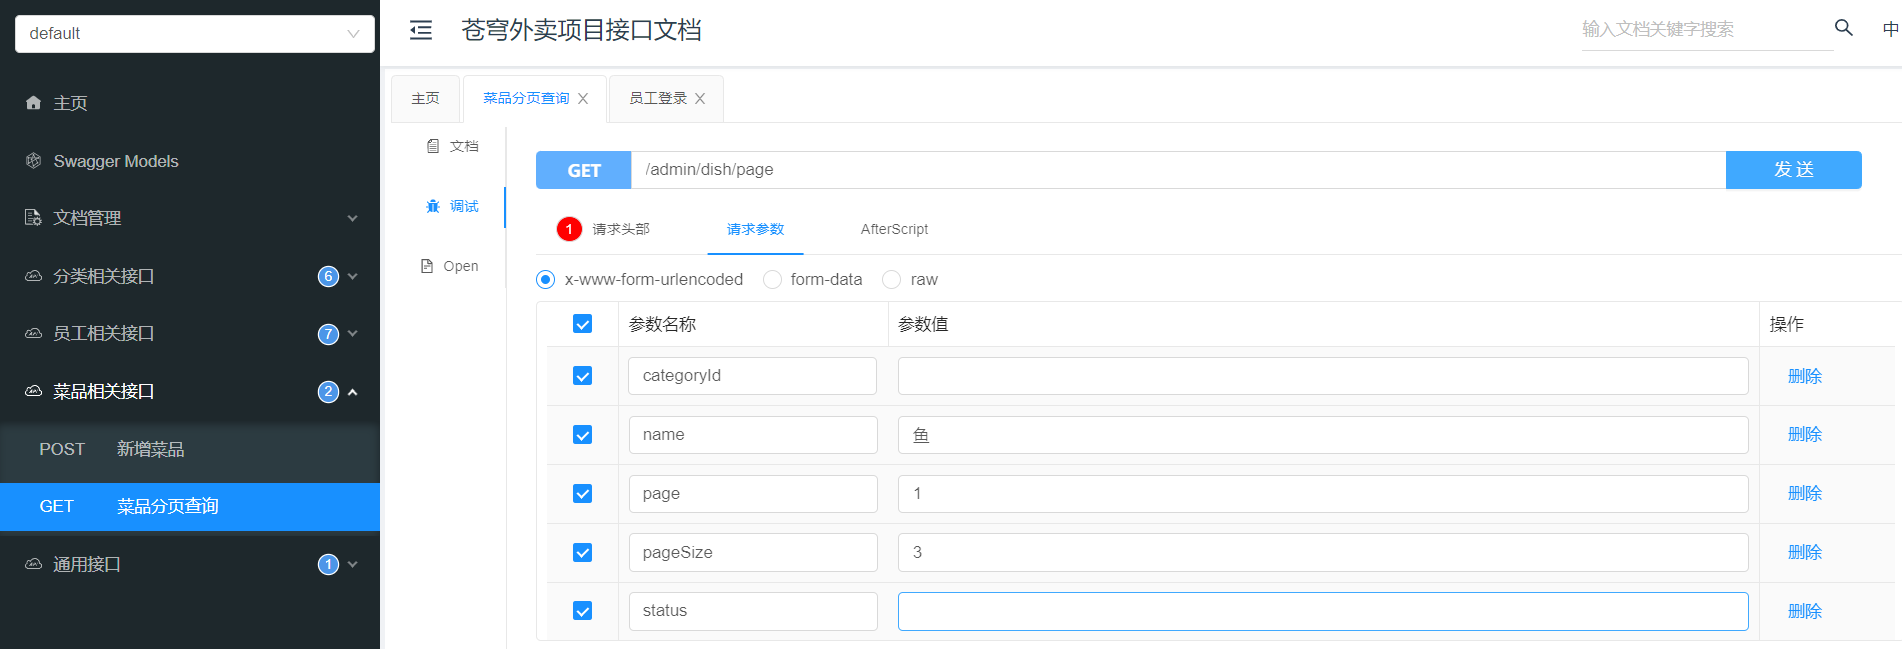  

**点击发送：**

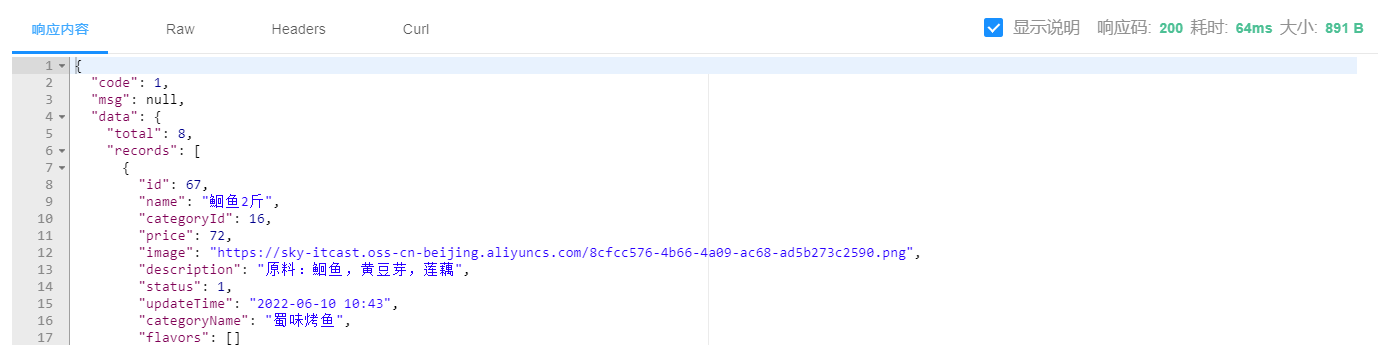 


#### 3.3.2 前后端联调测试

启动nginx,访问 http://localhost

**点击菜品管理**

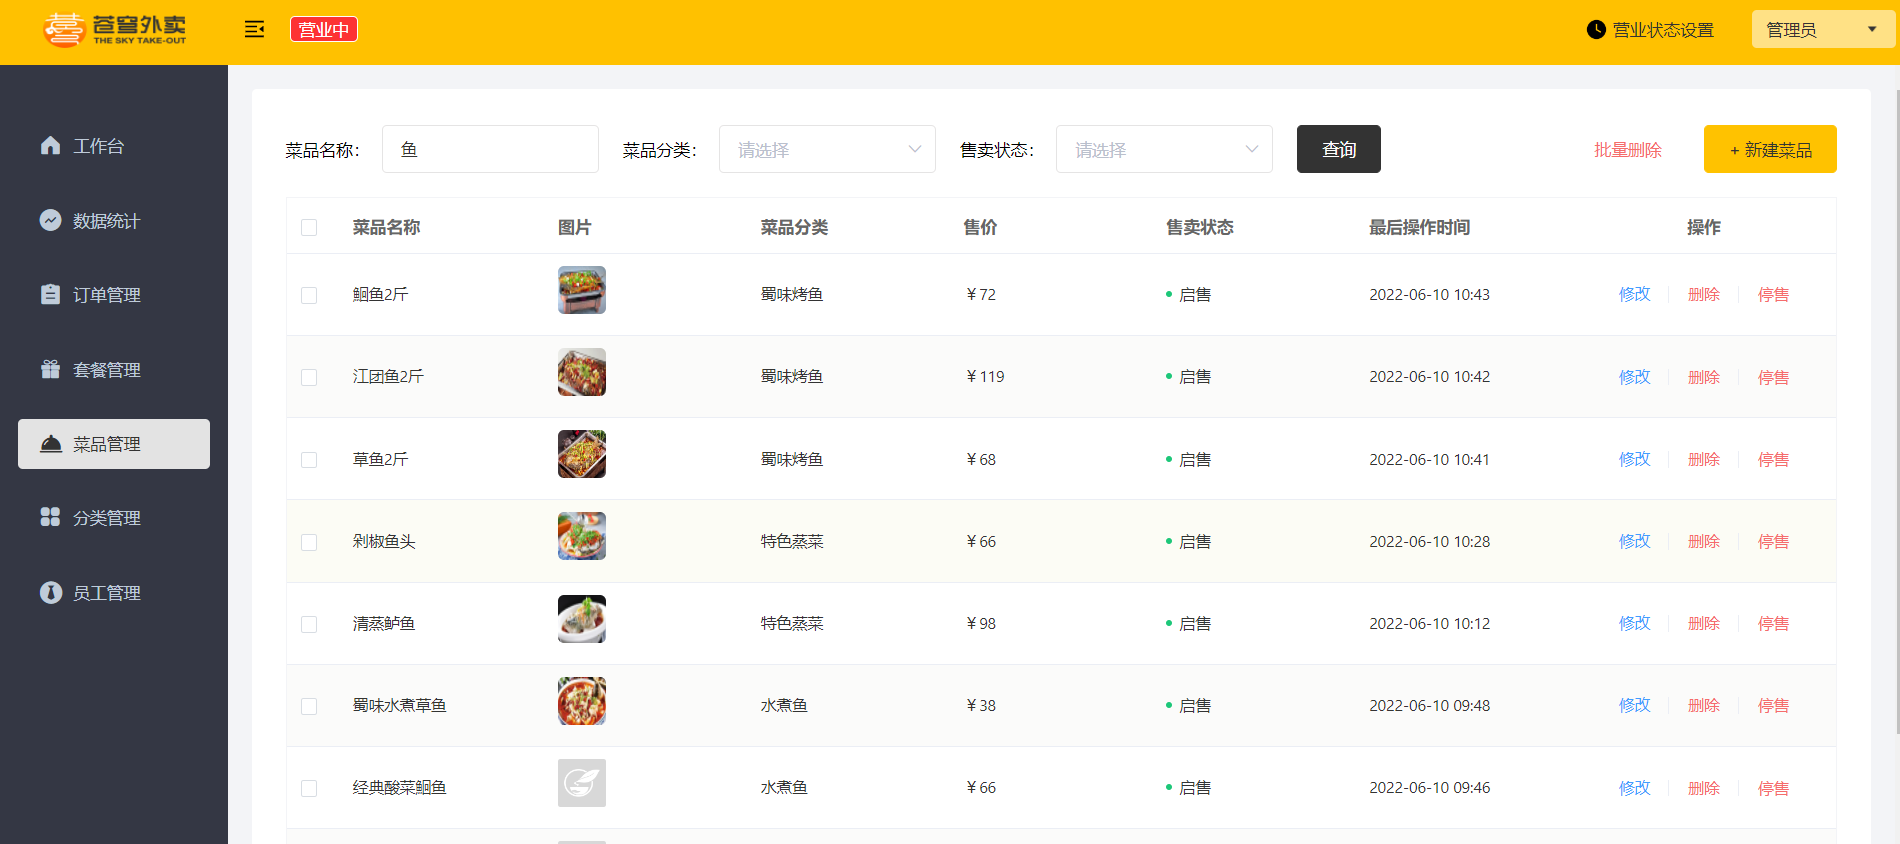 

数据成功查出。


### 分页测试矩阵（补充）

分别验证无筛选、名称筛选、分类筛选、status=0、status=1及组合筛选；检查空结果、下一页、最后一页和无效页码。记录total与records数量，不能只看第一页能显示。

核对categoryName、price、updateTime和图片实际加载结果。列表成功但图片403，应检查对象读取权限和URL；分类名称为null时检查category_id关联，不要把分页接口的成功响应当成图片和关联都有效的证明。


## 4. 删除菜品

> **PPT对照：** 第56—70页。


### 4.1 需求分析和设计

> **PPT对照：** 第57—60页。

#### 4.1.1 产品原型

在菜品列表页面，每个菜品后面对应的操作分别为**修改**、**删除**、**停售**，可通过删除功能完成对菜品及相关的数据进行删除。

**删除菜品原型：**

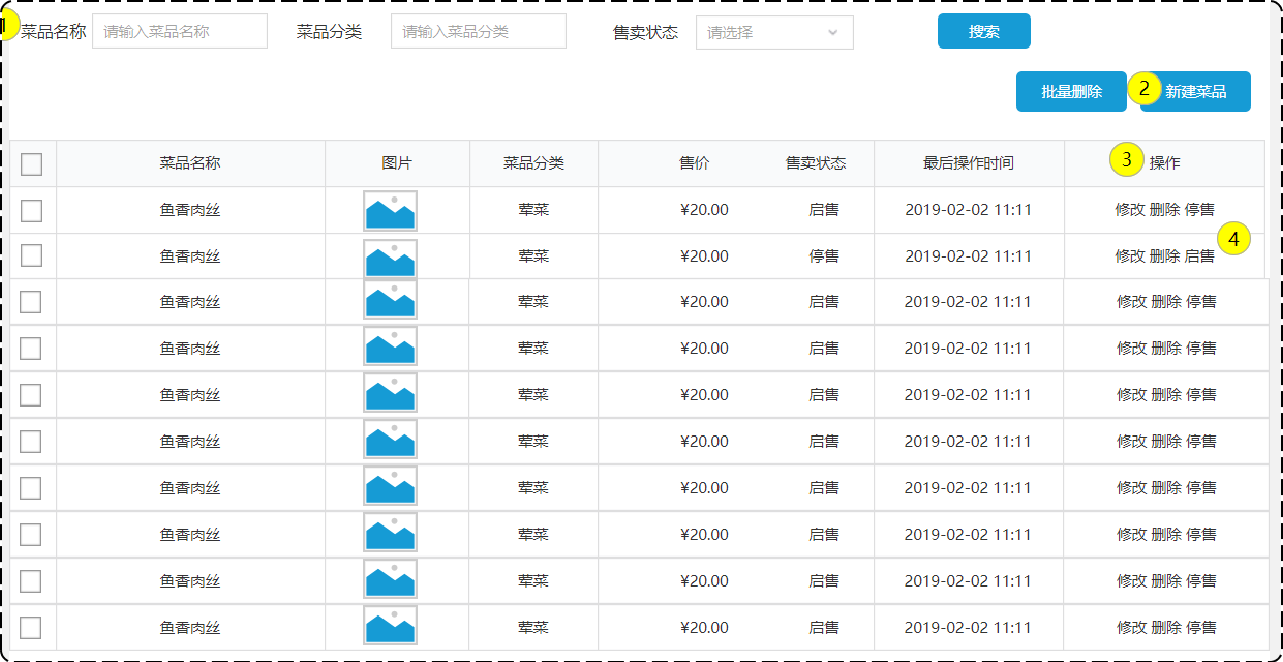 


**业务规则：**

- 可以一次删除一个菜品，也可以批量删除菜品
- 起售中的菜品不能删除
- 被套餐关联的菜品不能删除
- 删除菜品后，关联的口味数据也需要删除掉


#### 4.1.2 接口设计

根据上述原型图，设计出相应的接口。

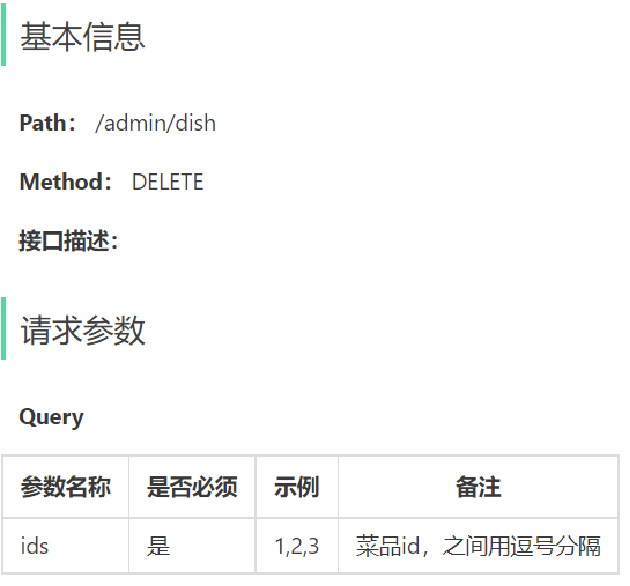 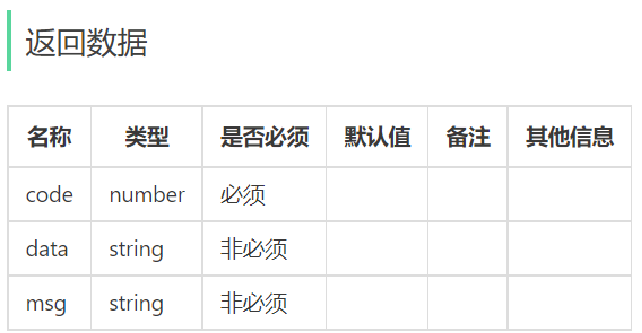

**注意：**删除一个菜品和批量删除菜品共用一个接口，故ids可包含多个菜品id,之间用逗号分隔。


#### 4.1.3 表设计

在进行删除菜品操作时，会涉及到以下三张表。

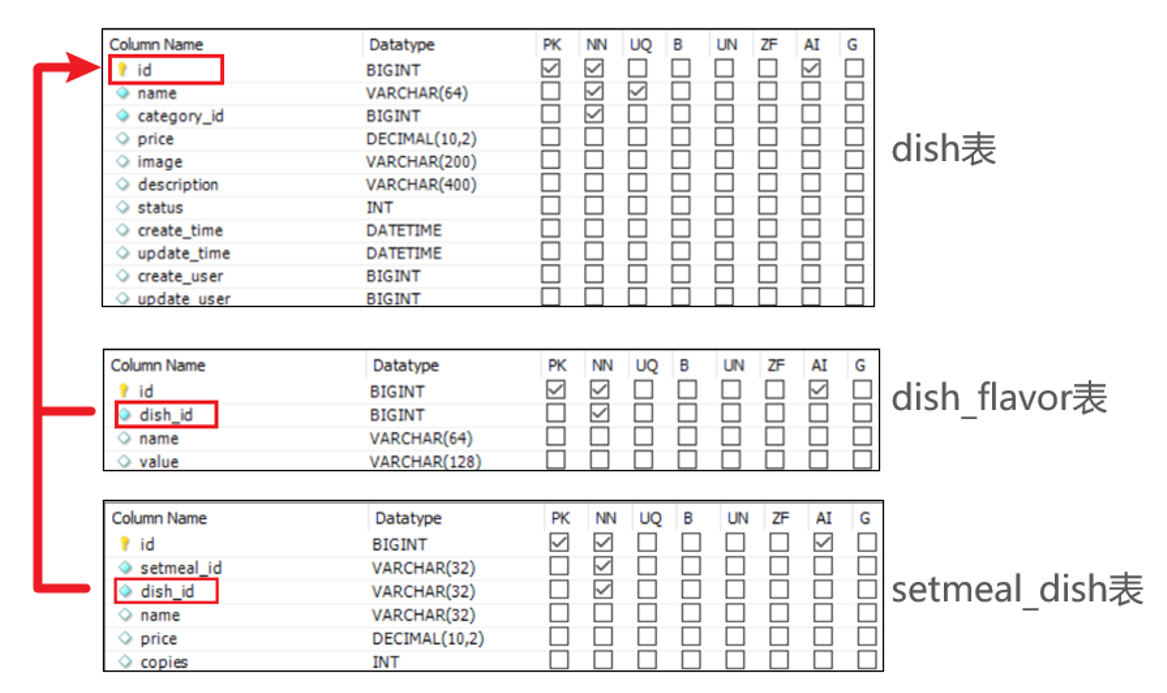 

**注意事项：**

- 在dish表中删除菜品基本数据时，同时，也要把关联在dish_flavor表中的数据一块删除。
- setmeal_dish表为菜品和套餐关联的中间表。
- 若删除的菜品数据关联着某个套餐，此时，删除失败。
- 若要删除套餐关联的菜品数据，先解除两者关联，再对菜品进行删除。


### 删除保护先于数据删除（补充）

必须同时满足：目标菜品存在、处于停售状态、没有任何套餐关联。关联套餐即使停售，本章规则也仍禁止删除它关联的菜品；不能只检查“起售套餐”。

单个id和多个id走同一套规则。批量删除中只要一个菜品不满足条件，整个请求应失败，不能先删除前面的合格菜品再返回错误。菜品删除成功时，相应口味也应消失，不留下孤立数据。

```text
校验ids → 检查所有菜品状态 → 检查套餐关联
    → 全部通过 → 删除菜品及其口味 → 提交事务
任何规则失败 → 抛业务异常 → 不删除本批次数据
```

删除业务不应通过顺便删setmeal_dish记录来绕过关联保护。该中间表在本章用于查询保护条件。


### 4.2 代码开发

> **PPT对照：** 第62—68页。

#### 4.1.2 Controller层

**根据删除菜品的接口定义在DishController中创建方法：**

```java
	/**
     * 菜品批量删除
     *
     * @param ids
     * @return
     */
    @DeleteMapping
    @ApiOperation("菜品批量删除")
    public Result delete(@RequestParam List<Long> ids) {
        log.info("菜品批量删除：{}", ids);
        dishService.deleteBatch(ids);//后绪步骤实现
        return Result.success();
    }
```


#### 4.2.2 Service层接口

**在DishService接口中声明deleteBatch方法：**

```java
	/**
     * 菜品批量删除
     *
     * @param ids
     */
    void deleteBatch(List<Long> ids);
```


#### 4.2.3 Service层实现类

**在DishServiceImpl中实现deleteBatch方法：**

```java
    @Autowired
    private SetmealDishMapper setmealDishMapper;
	/**
     * 菜品批量删除
     *
     * @param ids
     */
    @Transactional//事务
    public void deleteBatch(List<Long> ids) {
        //判断当前菜品是否能够删除---是否存在起售中的菜品？？
        for (Long id : ids) {
            Dish dish = dishMapper.getById(id);//后绪步骤实现
            if (dish.getStatus() == StatusConstant.ENABLE) {
                //当前菜品处于起售中，不能删除
                throw new DeletionNotAllowedException(MessageConstant.DISH_ON_SALE);
            }
        }

        //判断当前菜品是否能够删除---是否被套餐关联了？？
        List<Long> setmealIds = setmealDishMapper.getSetmealIdsByDishIds(ids);
        if (setmealIds != null && setmealIds.size() > 0) {
            //当前菜品被套餐关联了，不能删除
            throw new DeletionNotAllowedException(MessageConstant.DISH_BE_RELATED_BY_SETMEAL);
        }

        //删除菜品表中的菜品数据
        for (Long id : ids) {
            dishMapper.deleteById(id);//后绪步骤实现
            //删除菜品关联的口味数据
            dishFlavorMapper.deleteByDishId(id);//后绪步骤实现
        }
    }
```


#### 4.2.4 Mapper层

**在DishMapper中声明getById方法，并配置SQL：**

```java
	/**
     * 根据主键查询菜品
     *
     * @param id
     * @return
     */
    @Select("select * from dish where id = #{id}")
    Dish getById(Long id);
```

**创建SetmealDishMapper，声明getSetmealIdsByDishIds方法，并在xml文件中编写SQL：**

```java
package com.sky.mapper;

import com.sky.entity.SetmealDish;
import org.apache.ibatis.annotations.Delete;
import org.apache.ibatis.annotations.Mapper;
import java.util.List;

@Mapper
public interface SetmealDishMapper {
    /**
     * 根据菜品id查询对应的套餐id
     *
     * @param dishIds
     * @return
     */
    //select setmeal_id from setmeal_dish where dish_id in (1,2,3,4)
    List<Long> getSetmealIdsByDishIds(List<Long> dishIds);
}

```

SetmealDishMapper.xml

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.SetmealDishMapper">
    <select id="getSetmealIdsByDishIds" resultType="java.lang.Long">
        select setmeal_id from setmeal_dish where dish_id in
        <foreach collection="dishIds" item="dishId" separator="," open="(" close=")">
            #{dishId}
        </foreach>
    </select>
</mapper>
```

**在DishMapper.java中声明deleteById方法并配置SQL：**

```java
	/**
     * 根据主键删除菜品数据
     *
     * @param id
     */
    @Delete("delete from dish where id = #{id}")
    void deleteById(Long id);
```

**在DishFlavorMapper中声明deleteByDishId方法并配置SQL：**

```java
    /**
     * 根据菜品id删除对应的口味数据
     * @param dishId
     */
    @Delete("delete from dish_flavor where dish_id = #{dishId}")
    void deleteByDishId(Long dishId);
```


### 批量参数、事务和删除顺序（补充与勘误）

`@RequestParam List<Long> ids`接收 `?ids=1,2`，不是JSON数组请求体。建议显式写 `@RequestParam("ids")`，对空集合、null元素、非法id和重复id先作处理；原查询对不存在id直接getStatus会发生空指针，应在Service判空并返回明确业务错误。

SetmealDishMapper在讲义里参数名是dishIds、XML也用dishIds；PPT第66页两处用的是ids。两组各自一致，不能把一组Java声明和另一组XML混搭。推荐固定命名：

```java
List<Long> getSetmealIdsByDishIds(
        @org.apache.ibatis.annotations.Param("dishIds") List<Long> dishIds);
```

继续使用讲义XML的 `collection="dishIds"`。查询套餐id出现重复不影响“是否有关联”的判断；若要展示关联套餐列表，可以再去重。空集合应在进入IN查询之前拒绝，避免 `in ()`。

原方法已带 `@Transactional`，并先执行全部业务检查；这一点应保留。原代码在每轮先删dish再删dish_flavor，在课程逻辑外键表设计下可执行；如果后来给口味表创建了真实外键，必须按约束调整，通常先删子记录：

```java
// 放在所有状态与套餐关联校验通过之后，仍处于deleteBatch事务内。
for (Long id : ids) {
    dishFlavorMapper.deleteByDishId(id);
    dishMapper.deleteById(id);
}
```

该顺序让口味删除和菜品删除共同回滚，不表示删除检查可以省略。权限检查及“检查完成后其他事务又新增关联”的并发问题也不会仅靠@Transactional自动解决；严格要求时需约束、锁或统一关联写入规则。

本章逐个查询、逐个删除的方式便于理解，较大批次会产生较多SQL。后续可考虑集合查询与批量删除，但必须保留整批规则、空集合检查及事务语义。

原文4.2下面误写一个4.1.2编号，属于排版问题，不影响代码执行。


### 4.3 功能测试

> **PPT对照：** 第70页。

既可以通过Swagger接口文档进行测试，也可以通过前后端联调测试，接下来，我们直接使用**前后端联调测试**。

进入到菜品列表查询页面

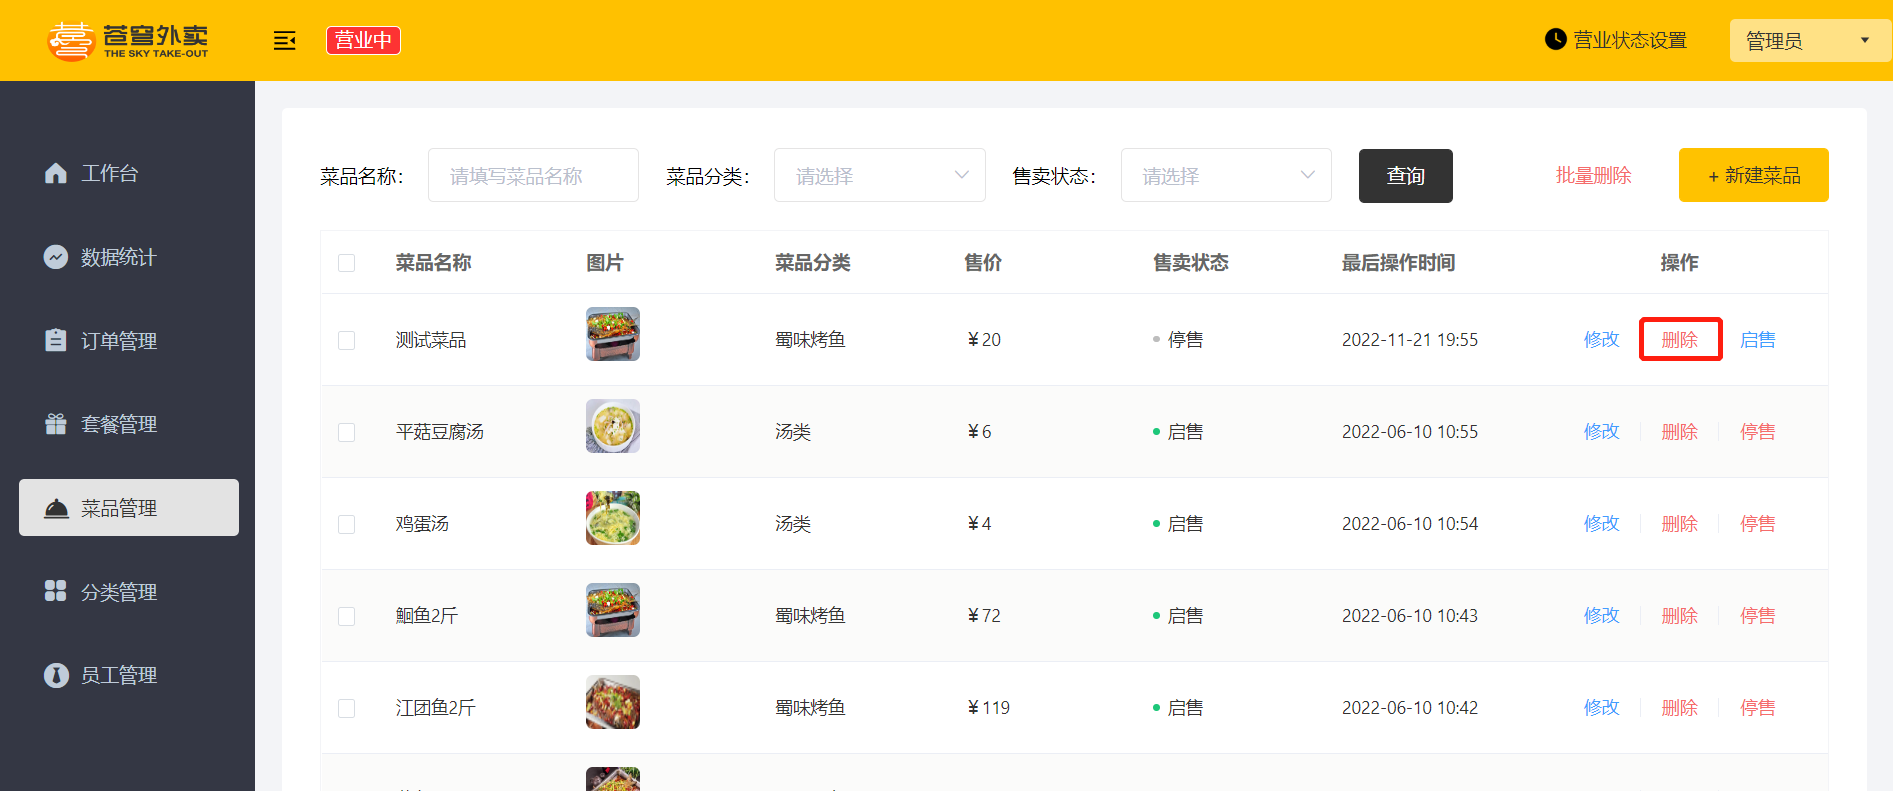 

对测试菜品进行删除操作

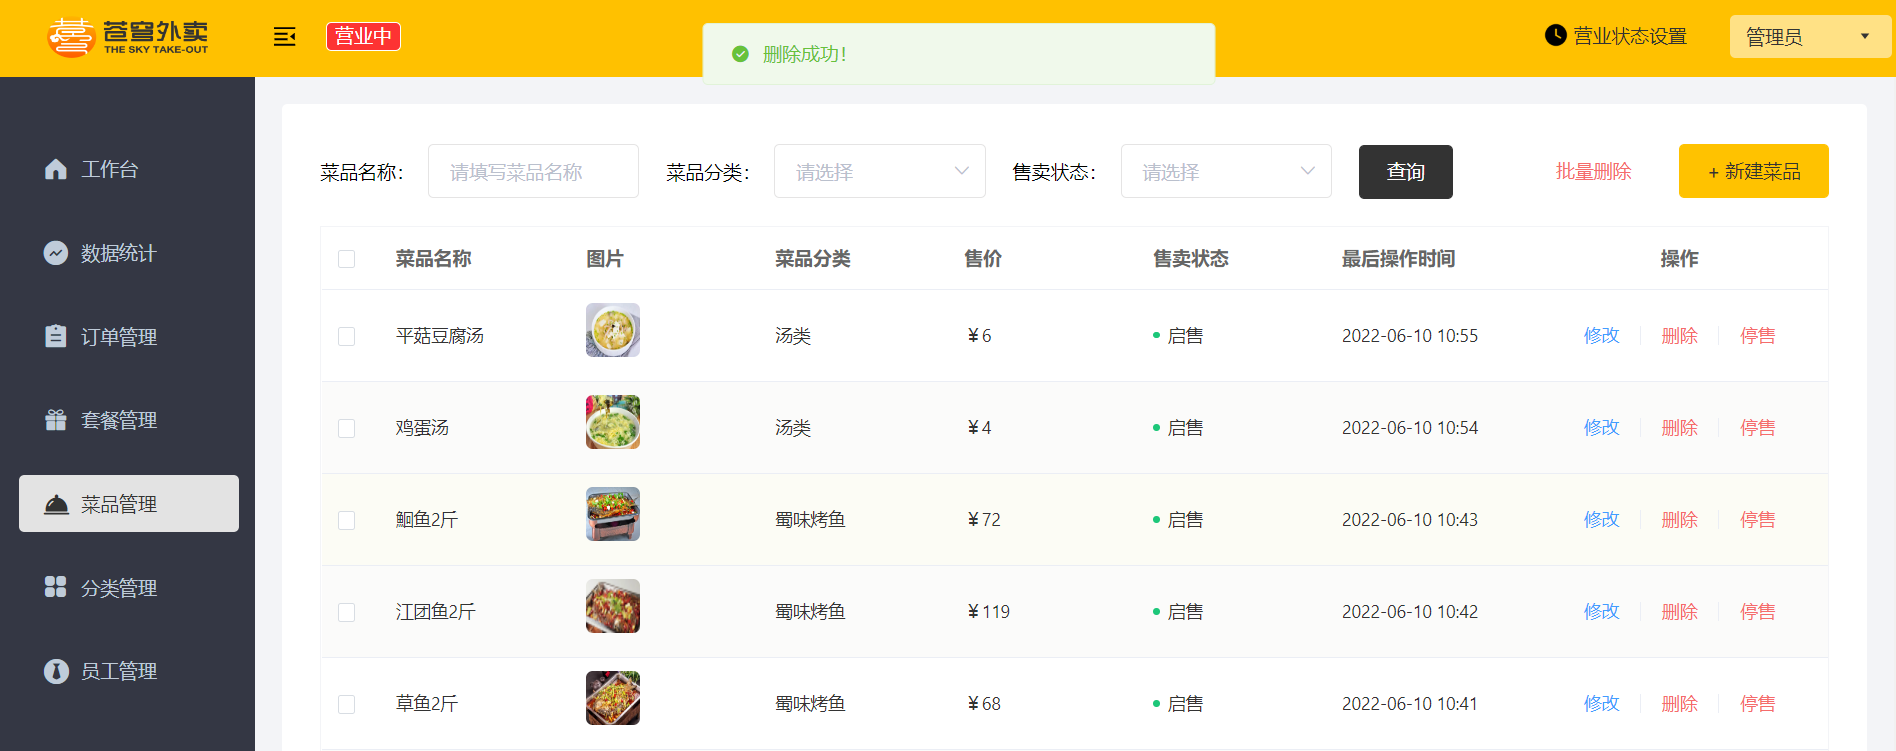 

同时，进到dish表和dish_flavor两个表查看**测试菜品**的相关数据都已被成功删除。


再次，删除状态为启售的菜品

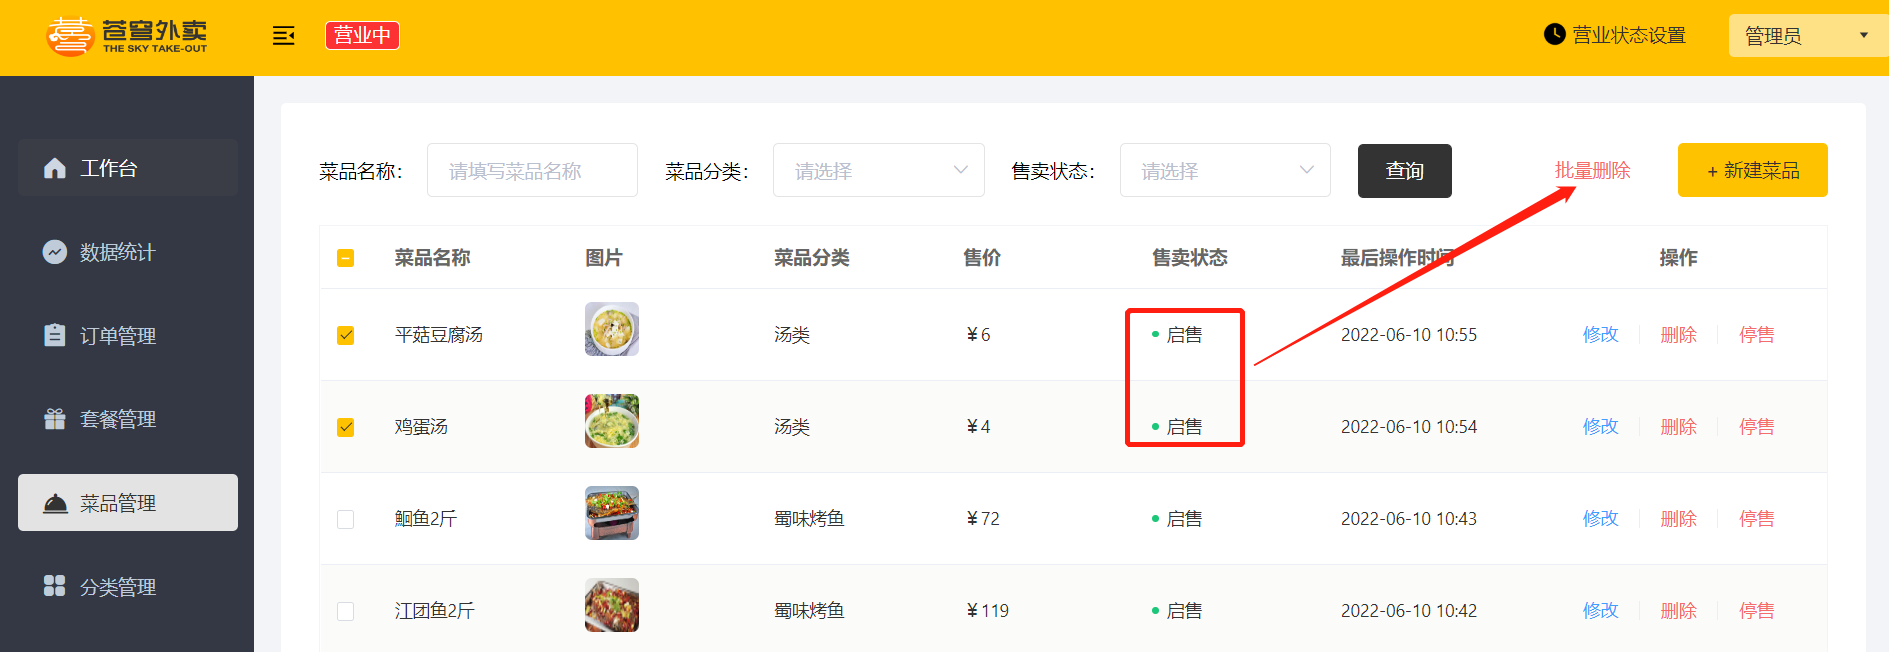 

点击批量删除

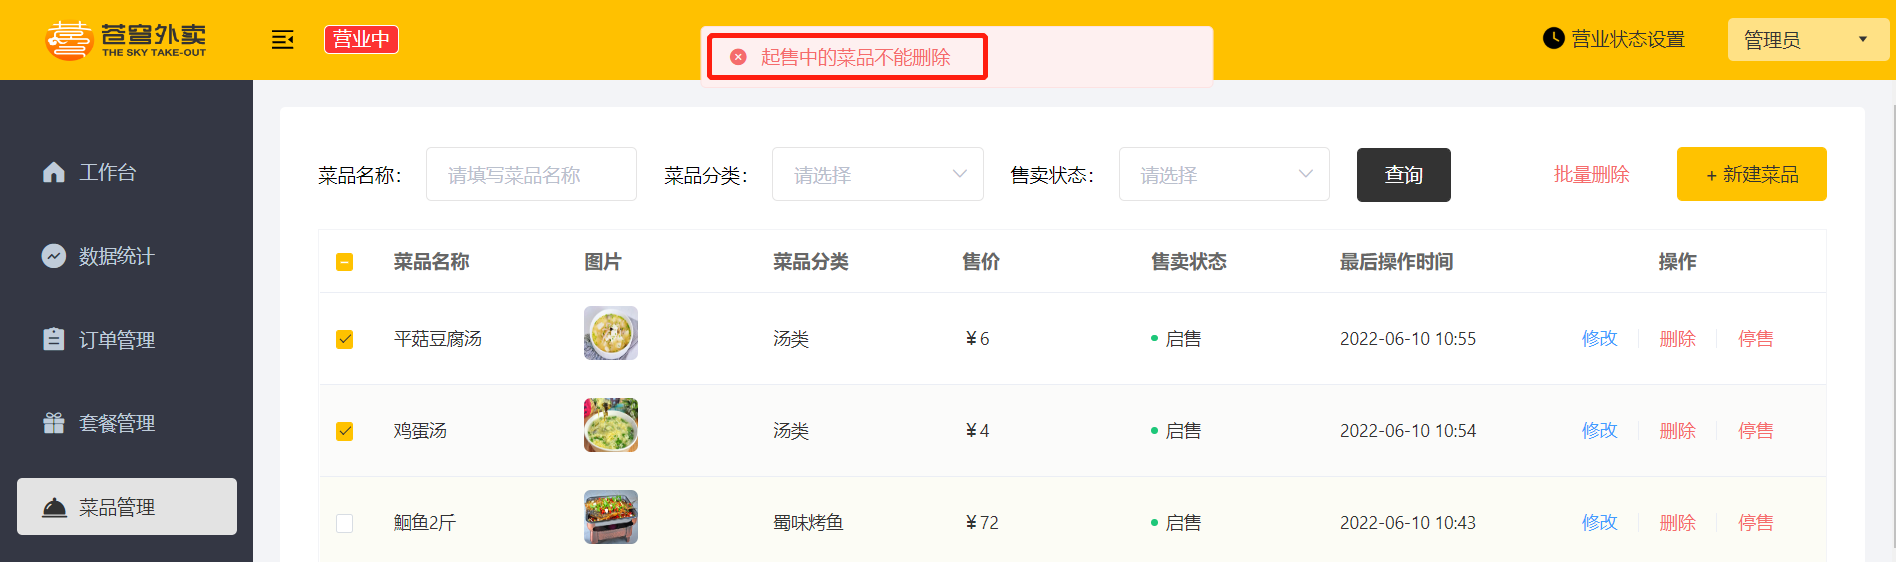 

删除失败，因为起售中的菜品不能删除。


### 删除必须覆盖失败分支（补充）

| 场景 | 预期 |
| --- | --- |
| 单个停售、未关联套餐的菜品 | 菜品与口味一起删除 |
| 多个均可删除的菜品 | 整批删除成功 |
| 单个起售菜品 | 禁止删除，全部数据保留 |
| 关联套餐的停售菜品 | 禁止删除，关联记录保留 |
| 批次混合可删除和不可删除项 | 整批失败，可删除项也保留 |
| 不存在的id、空列表、非法参数 | 明确错误，无空指针或无条件删除 |
| 删除中途数据库异常 | 已执行的本批次删除回滚 |

测试后同时查dish、dish_flavor与setmeal_dish，确认成功时无孤立口味，失败时原数据完整。页面选中多行并返回一条提示，不能单独证明事务已正确实现。


### 4.4 代码提交

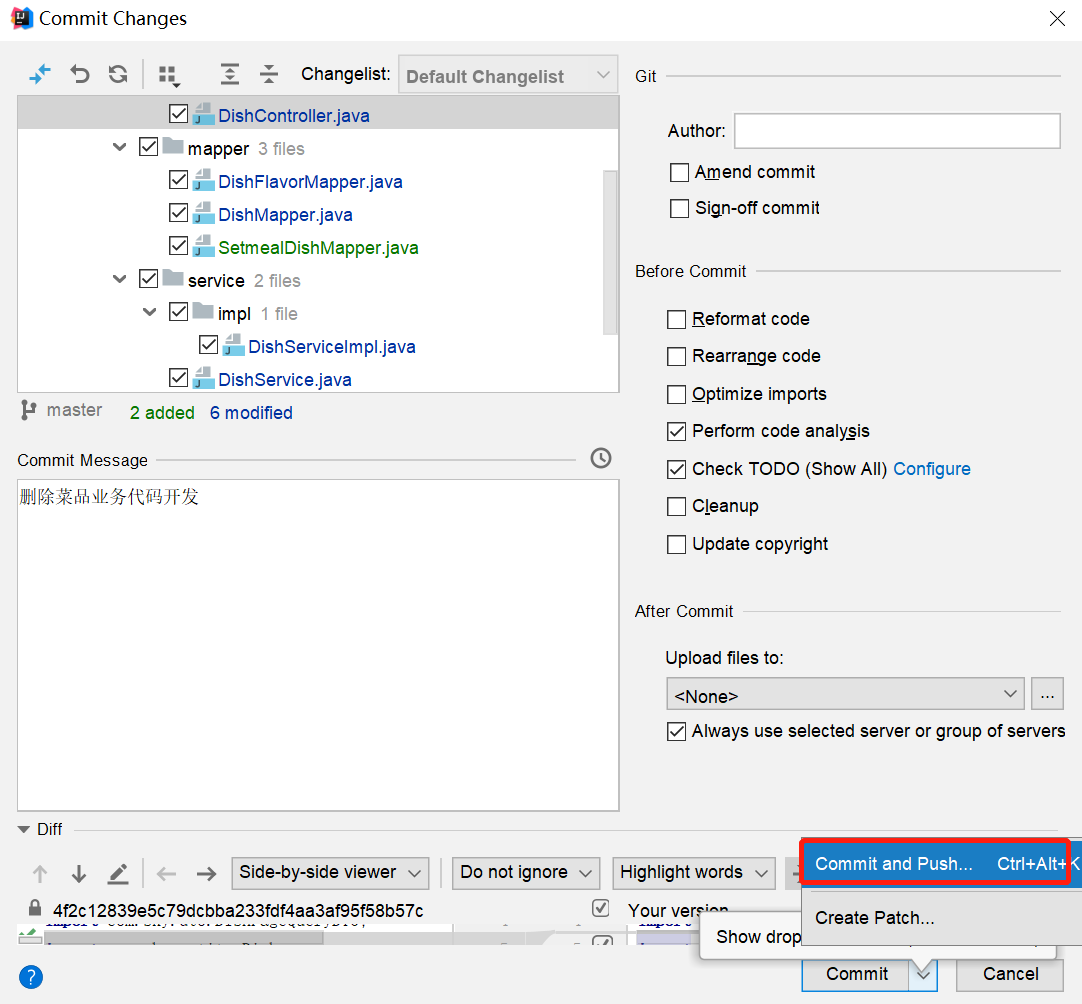 

后续步骤和上述功能代码提交一致，不再赘述。


## 5. 修改菜品

> **PPT对照：** 第72—88页。


### 5.1 需求分析和设计

> **PPT对照：** 第73—76页。

#### 5.1.1 产品原型

在菜品管理列表页面点击修改按钮，跳转到修改菜品页面，在修改页面回显菜品相关信息并进行修改，最后点击保存按钮完成修改操作。

**修改菜品原型：**

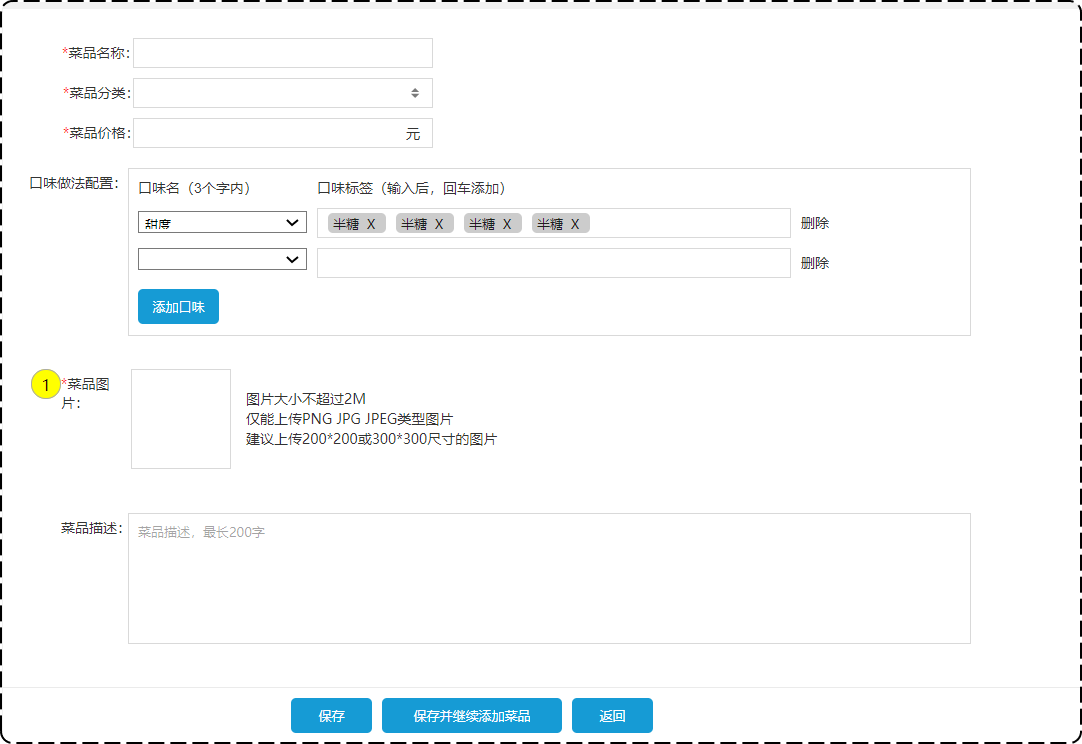 


#### 5.1.2 接口设计

通过对上述原型图进行分析，该页面共涉及4个接口。

**接口：**

- 根据id查询菜品
- 根据类型查询分类(已实现)
- 文件上传(已实现)
- 修改菜品

我们只需要实现**根据id查询菜品**和**修改菜品**两个接口，接下来，我们来重点分析这两个接口。

**1). 根据id查询菜品**

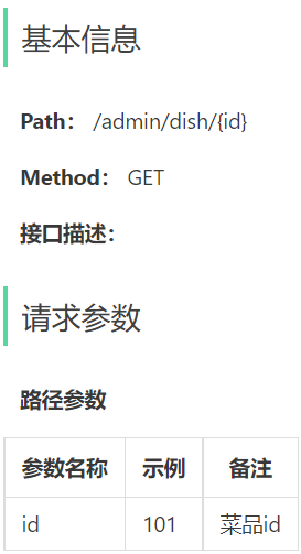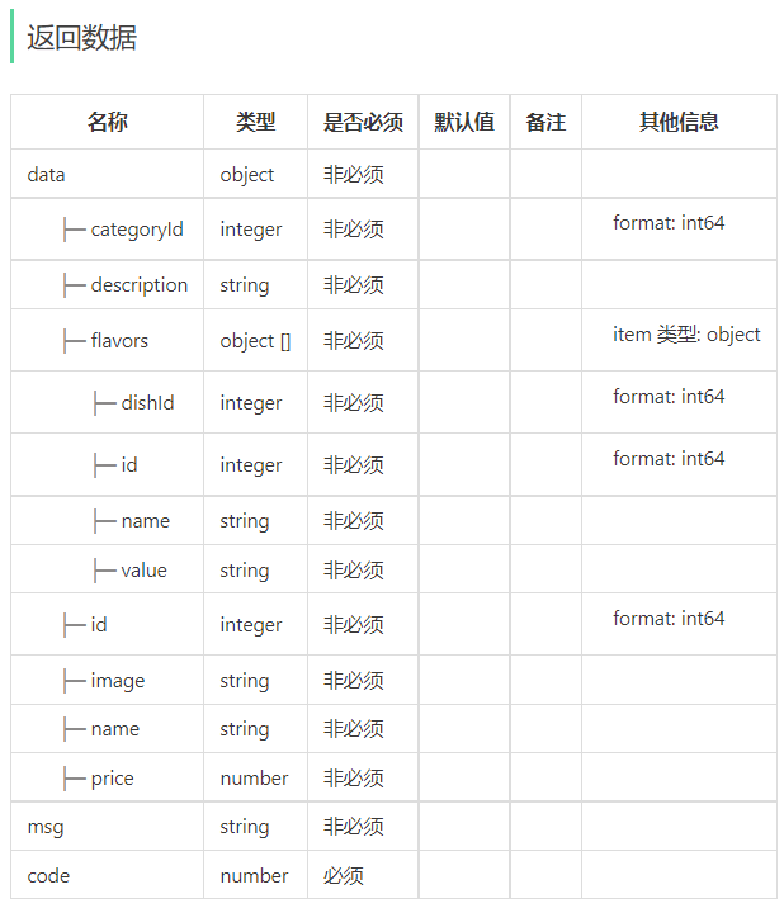

**2). 修改菜品**

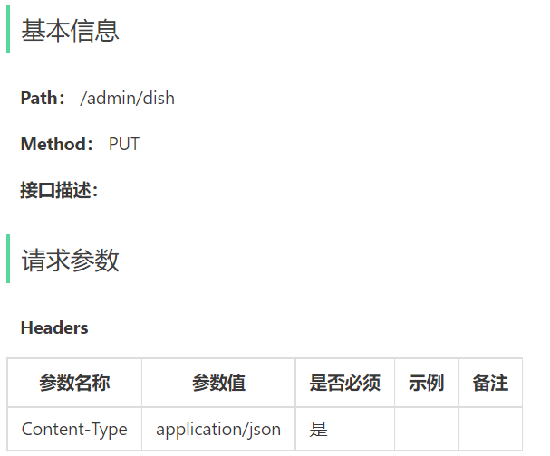 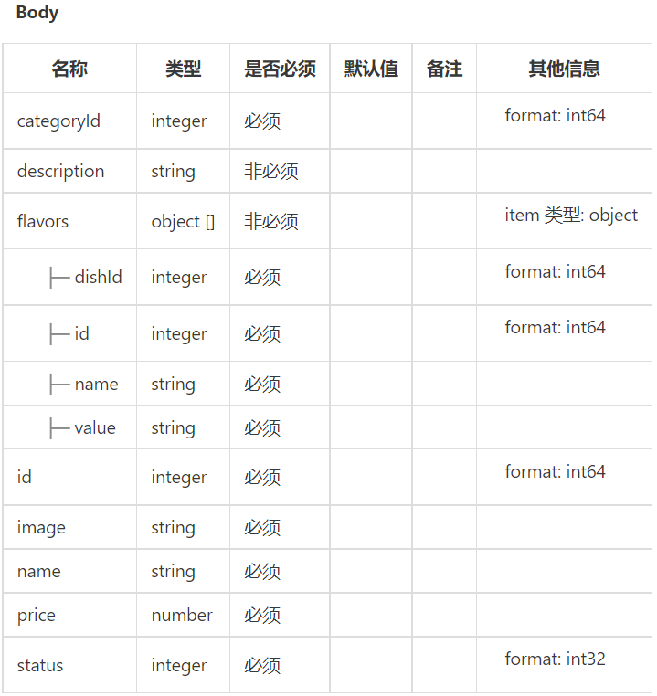


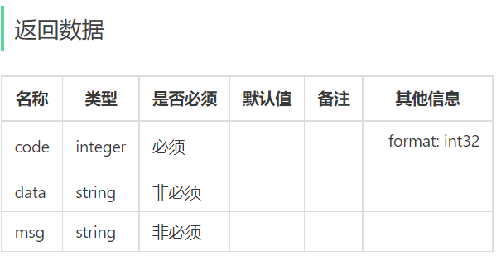 

**注:因为是修改功能，请求方式可设置为PUT。**


### 编辑先回显，保存时替换口味（补充）

GET回显组合菜品基本信息和完整口味，分类下拉框与上传接口复用已有实现。PUT提交目标id、新基本信息和本次完整的口味集合。

本章采用“删除旧口味，再插入新口味”的整体替换方案，口味行id可能改变。它不是按每条口味id逐项更新，也不是只把新口味追加到原列表。

flavors为空列表表示删除全部口味。原代码flavors=null也会删除全部旧口味，因为deleteByDishId在判空之前已经执行。DTO默认初始化为新ArrayList，遗漏该属性时通常也是空列表；因此前端修改时应提交完整集合。如果希望null代表不修改、[]代表清空，要另行定义并实现该约定，不能靠默认值猜测。


### 5.2 代码开发

> **PPT对照：** 第78—86页。

#### 5.2.1 根据id查询菜品实现

**1). Controller层**

**根据id查询菜品的接口定义在DishController中创建方法：**

```java
    /**
     * 根据id查询菜品
     *
     * @param id
     * @return
     */
    @GetMapping("/{id}")
    @ApiOperation("根据id查询菜品")
    public Result<DishVO> getById(@PathVariable Long id) {
        log.info("根据id查询菜品：{}", id);
        DishVO dishVO = dishService.getByIdWithFlavor(id);//后绪步骤实现
        return Result.success(dishVO);
    }
```


**2). Service层接口**

**在DishService接口中声明getByIdWithFlavor方法：**

```java
	/**
     * 根据id查询菜品和对应的口味数据
     *
     * @param id
     * @return
     */
    DishVO getByIdWithFlavor(Long id);
```


**3). Service层实现类**

**在DishServiceImpl中实现getByIdWithFlavor方法：**

```java
	/**
     * 根据id查询菜品和对应的口味数据
     *
     * @param id
     * @return
     */
    public DishVO getByIdWithFlavor(Long id) {
        //根据id查询菜品数据
        Dish dish = dishMapper.getById(id);

        //根据菜品id查询口味数据
        List<DishFlavor> dishFlavors = dishFlavorMapper.getByDishId(id);//后绪步骤实现

        //将查询到的数据封装到VO
        DishVO dishVO = new DishVO();
        BeanUtils.copyProperties(dish, dishVO);
        dishVO.setFlavors(dishFlavors);

        return dishVO;
    }
```


**4). Mapper层**

**在DishFlavorMapper中声明getByDishId方法，并配置SQL：**

```java
    /**
     * 根据菜品id查询对应的口味数据
     * @param dishId
     * @return
     */
    @Select("select * from dish_flavor where dish_id = #{dishId}")
    List<DishFlavor> getByDishId(Long dishId);
```


#### 5.2.1 修改菜品实现

**1). Controller层**

**根据修改菜品的接口定义在DishController中创建方法：**

```java
	/**
     * 修改菜品
     *
     * @param dishDTO
     * @return
     */
    @PutMapping
    @ApiOperation("修改菜品")
    public Result update(@RequestBody DishDTO dishDTO) {
        log.info("修改菜品：{}", dishDTO);
        dishService.updateWithFlavor(dishDTO);
        return Result.success();
    }
```


**2). Service层接口**

**在DishService接口中声明updateWithFlavor方法：**

```java
	/**
     * 根据id修改菜品基本信息和对应的口味信息
     *
     * @param dishDTO
     */
    void updateWithFlavor(DishDTO dishDTO);
```


**3). Service层实现类**

**在DishServiceImpl中实现updateWithFlavor方法：**

```java
	/**
     * 根据id修改菜品基本信息和对应的口味信息
     *
     * @param dishDTO
     */
    public void updateWithFlavor(DishDTO dishDTO) {
        Dish dish = new Dish();
        BeanUtils.copyProperties(dishDTO, dish);

        //修改菜品表基本信息
        dishMapper.update(dish);

        //删除原有的口味数据
        dishFlavorMapper.deleteByDishId(dishDTO.getId());

        //重新插入口味数据
        List<DishFlavor> flavors = dishDTO.getFlavors();
        if (flavors != null && flavors.size() > 0) {
            flavors.forEach(dishFlavor -> {
                dishFlavor.setDishId(dishDTO.getId());
            });
            //向口味表插入n条数据
            dishFlavorMapper.insertBatch(flavors);
        }
    }
```


**4). Mapper层**

**在DishMapper中，声明update方法：**

```java
	/**
     * 根据id动态修改菜品数据
     *
     * @param dish
     */
    @AutoFill(value = OperationType.UPDATE)
    void update(Dish dish);
```

**并在DishMapper.xml文件中编写SQL:**

```xml
<update id="update">
        update dish
        <set>
            <if test="name != null">name = #{name},</if>
            <if test="categoryId != null">category_id = #{categoryId},</if>
            <if test="price != null">price = #{price},</if>
            <if test="image != null">image = #{image},</if>
            <if test="description != null">description = #{description},</if>
            <if test="status != null">status = #{status},</if>
            <if test="updateTime != null">update_time = #{updateTime},</if>
            <if test="updateUser != null">update_user = #{updateUser},</if>
        </set>
        where id = #{id}
</update>
```


### 修改菜品事务勘误（重点）

讲义updateWithFlavor没有 `@Transactional`，但PPT第84页有。方法包含修改dish、删除原口味、插入新口味三组写入，必须作为整体提交或回滚，否则新口味插入失败时可能已改价格并删光旧口味。

在已有DishServiceImpl里替换该方法，沿用已注入的两个Mapper；以下补充增加事务、目标存在性检查，并明确口味整体替换。使用完整类名表示无需为异常补充新类。

```java
@Override
@org.springframework.transaction.annotation.Transactional(rollbackFor = Exception.class)
public void updateWithFlavor(DishDTO dishDTO) {
    if (dishDTO == null || dishDTO.getId() == null || dishDTO.getId() <= 0) {
        throw new IllegalArgumentException("修改菜品必须提供有效id");
    }
    Long dishId = dishDTO.getId();
    Dish existing = dishMapper.getById(dishId);
    if (existing == null) {
        throw new IllegalArgumentException("菜品不存在");
    }

    // 在此复用名称、分类、价格、图片、状态与操作权限校验。
    // 对口味先完成校验，再开始写入。
    List<DishFlavor> flavors = dishDTO.getFlavors();
    if (flavors != null) {
        for (DishFlavor flavor : flavors) {
            if (flavor == null || flavor.getName() == null
                    || flavor.getName().trim().isEmpty()
                    || flavor.getValue() == null) {
                throw new IllegalArgumentException("口味数据不完整");
            }
            flavor.setId(null);
            flavor.setDishId(dishId);
        }
    }

    Dish dish = new Dish();
    BeanUtils.copyProperties(dishDTO, dish);
    // Mapper的@AutoFill(UPDATE)设置updateTime与updateUser。
    dishMapper.update(dish);

    // 沿用课程整体替换语义：null或空列表均清空旧口味。
    dishFlavorMapper.deleteByDishId(dishId);
    if (flavors != null && !flavors.isEmpty()) {
        dishFlavorMapper.insertBatch(flavors);
    }
}
```

示例的IllegalArgumentException需由已有统一异常处理器映射为业务错误，或换成工程现有业务异常；没有对应处理时不能期待自动返回友好的Result。注释中的基本信息规则仍需按实际项目落地，这里重点修正事务并避免不存在记录被继续处理。

课程运行时业务异常默认能触发回滚；示例明确rollbackFor以覆盖受检异常。要让事务生效，Controller应调用Spring注入的Service代理，不能new实现类，也不要在同一个类里自调用该方法。不要捕获插入异常后返回成功，这会破坏失败回滚的预期。

#### 回显判空与VO内容

getByIdWithFlavor先查dish；不存在时应先报错，再查询口味和复制属性。BeanUtils对null源对象会报错。回显方法填入flavors，但没有另查分类名称；前端通过categoryId选择下拉框即可，不要以为此方法也必然返回已填充的categoryName。

#### 动态更新不会自动清空字段

原XML `name != null` 等条件表示null跳过更新，空字符串则会写入。description传null不会清空旧描述；是否允许传空字符串清空，应按表单约定与校验规则定义。创建时间、创建人不在update SQL内，应保留；更新时间和修改人由切面更新。

原DishMapper.update返回void，无法仅靠返回值知道影响行数。提前查询处理了常见的不存在情况，但不能消除并发删除；若必须严格判断写入结果，可将Mapper改为int并核对影响行数。

原讲义有两个5.2.1标题，分别为回显与修改，第二个应理解为下一小节。原文编号保留，跟练时按方法用途区分。


### 5.3 功能测试

> **PPT对照：** 第88页。

本次测试直接通过**前后端联调测试** ，可使用Debug方式启动项目，观察运行中步骤。

进入菜品列表查询页面，对第一个菜品的价格进行修改

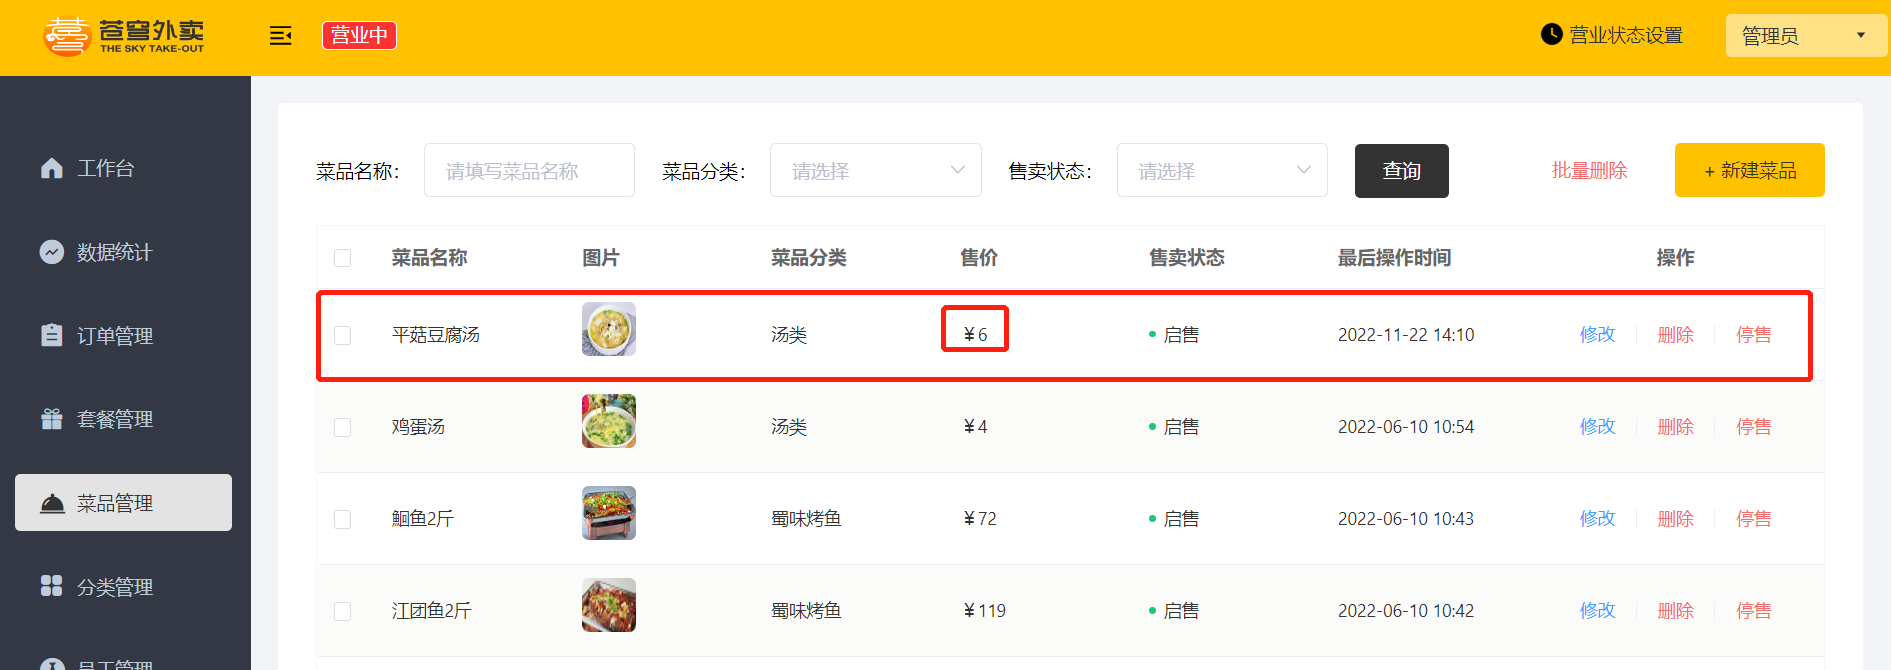 

点击修改，回显成功

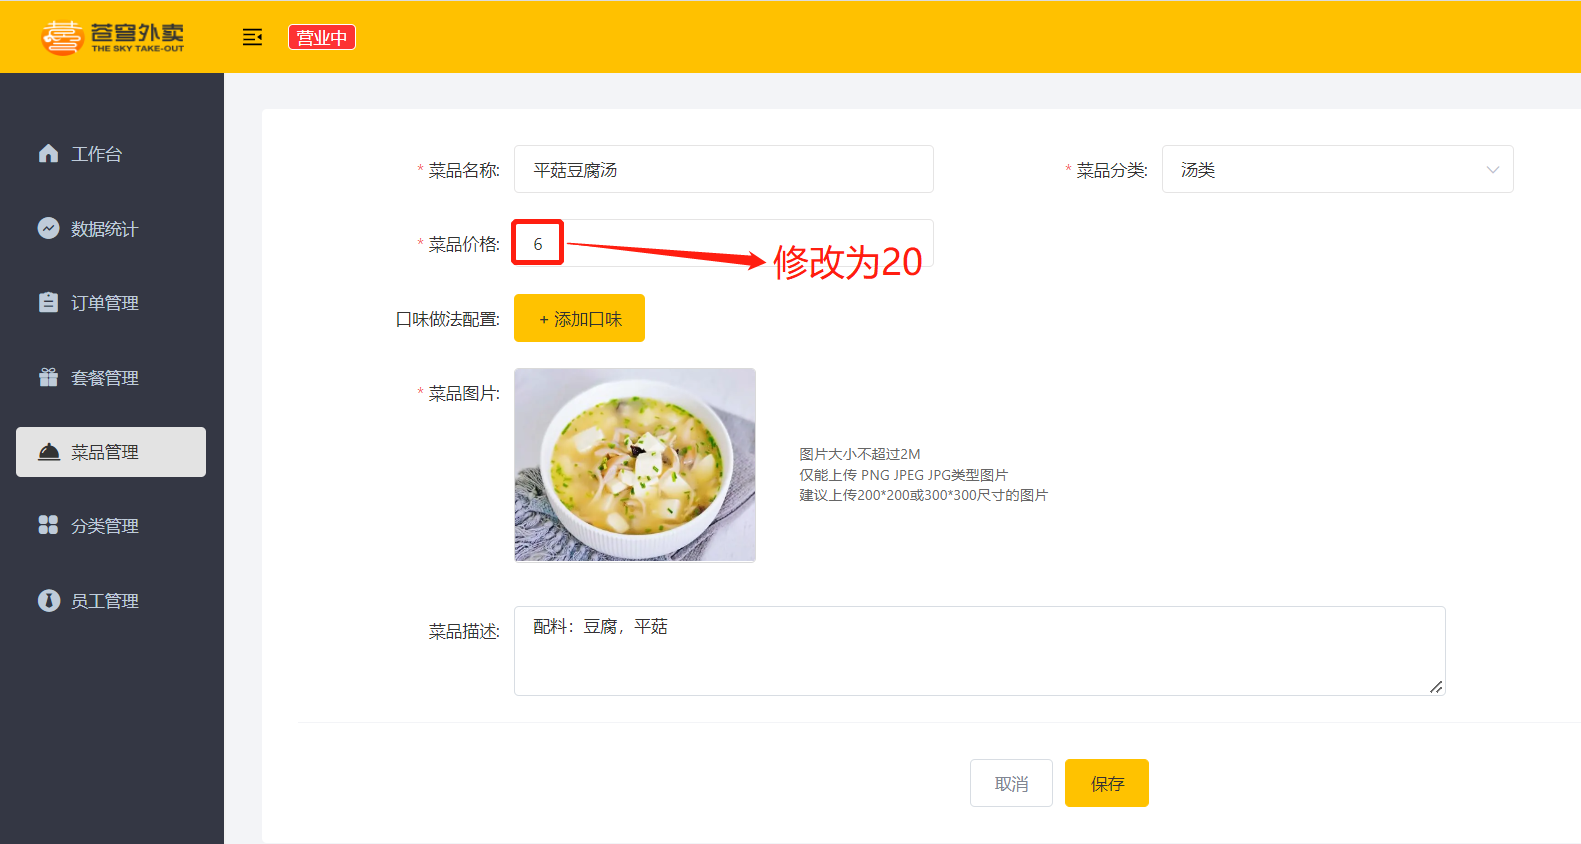 

菜品价格修改后，点击保存

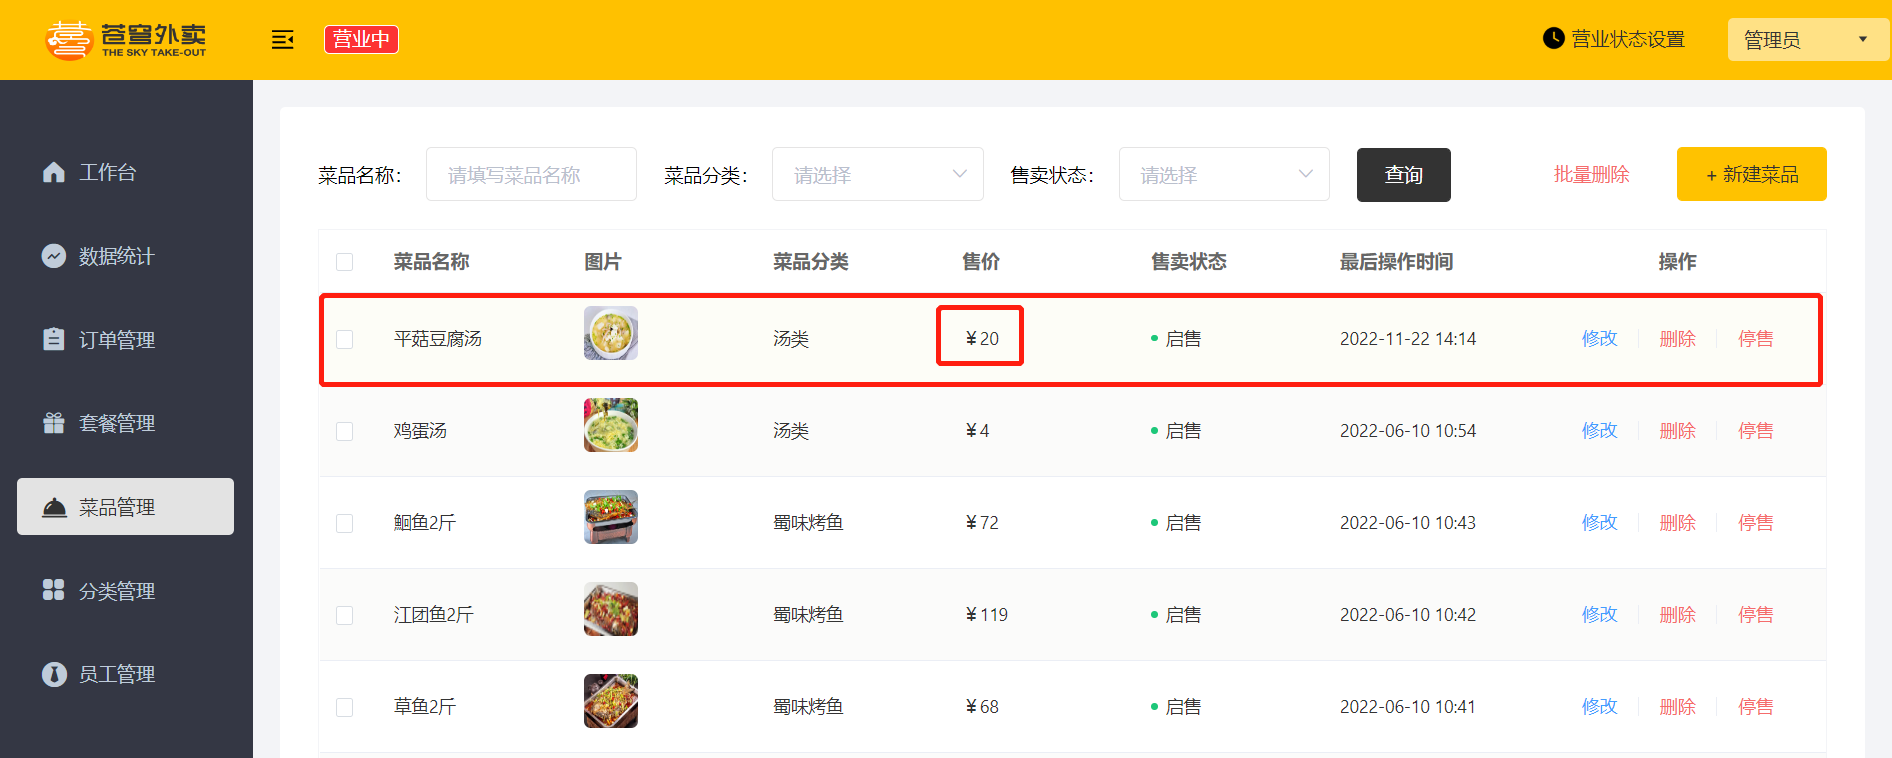 

修改成功


### 修改与回滚验收（补充）

先保存一份测试菜品的原价格与口味，再GET回显，修改价格和口味，PUT保存后重新查询。核对基本字段、口味名称与值、所有dish_id、updateTime和updateUser；createTime/createUser应保持不变。

依次测试：保留口味、增加口味、删掉部分口味、提交空列表清空全部口味，以及不存在id、重复名称和非法分类。保存失败后重新回显，不能只看页面提示。

在测试环境故意让最后的口味插入失败，确认价格回到原值、原口味仍完整、没有部分新口味。若价格已变或原口味丢失，检查事务注解、代理调用、异常是否被吞掉及数据库表的事务支持。


### 5.4 代码提交

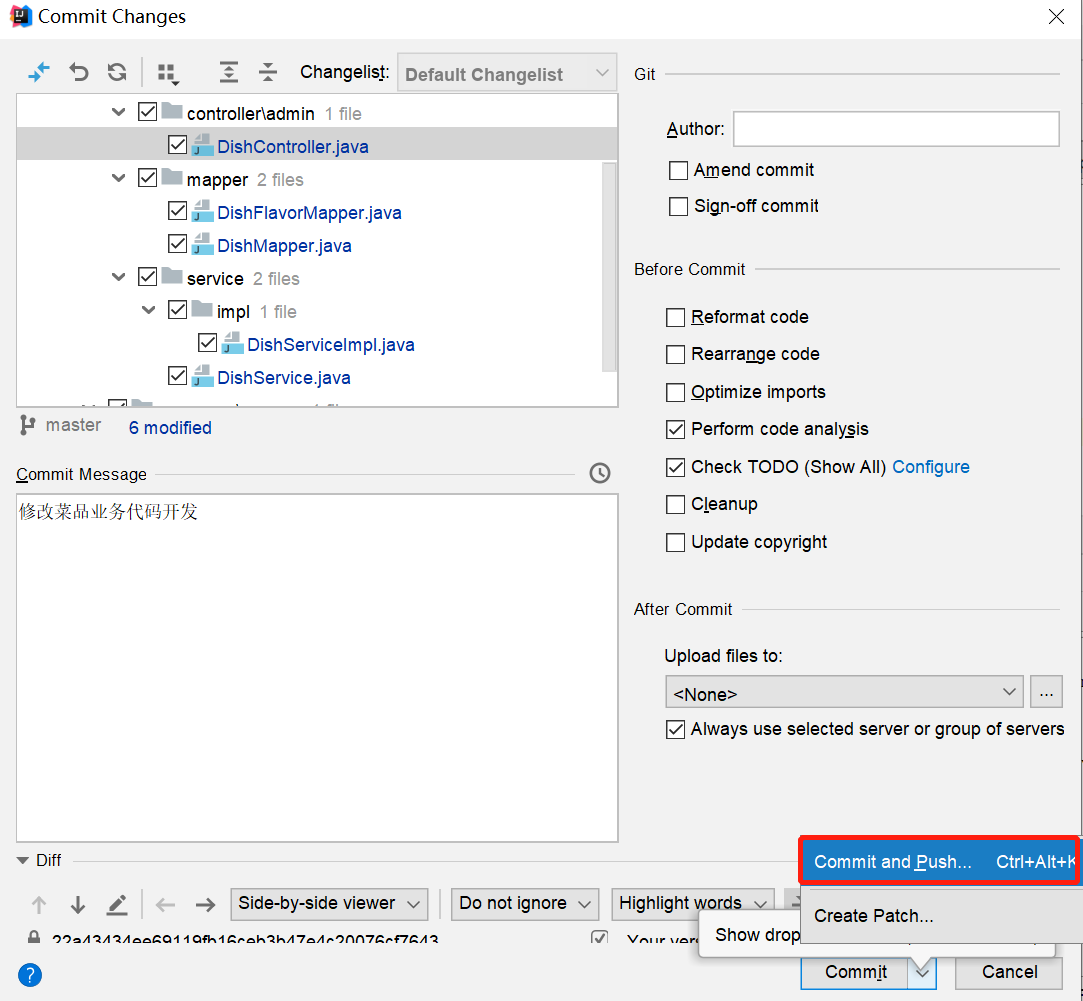 

后续步骤和上述功能代码提交一致，不再赘述。


## 复习速查与本章验收（补充）

| 知识点 | 核心记忆 |
| --- | --- |
| AutoFill | Mapper方法注解表达INSERT/UPDATE，前置切面修改实体 |
| 反射 | setter名称与参数类型必须匹配，失败不能继续假装成功 |
| 公共字段 | INSERT四项，UPDATE两项；SQL必须实际写入 |
| 文件上传 | MultipartFile接收file，OSS存对象，dish.image保存访问信息 |
| OSS结果 | putObject成功才返回成功地址；权限决定是否能直接访问 |
| 主键回填 | useGeneratedKeys与keyProperty=id，把生成id交给口味 |
| 一对多保存 | 插入dish后给flavors设置dishId，非空再insertBatch |
| 分页 | Query DTO + PageHelper + LEFT JOIN分类名称 |
| 批量删除 | 全部检查通过后删除，起售或套餐关联任一成立均禁止 |
| 修改口味 | 先删后插是整体替换，事务保护所有写入 |

### 问题排查

| 表现 | 优先检查 |
| --- | --- |
| 审计字段为空 | AutoFill注解、切面、BaseContext、SQL字段 |
| NoSuchMethodException | setter名字、Long/long、继承方法查找范围 |
| 启动时配置解析失败 | 激活环境、同名自引用、环境变量是否设置 |
| OSS返回成功但找不到图片 | 原工具是否吞异常，Endpoint与Bucket是否对应 |
| 上传接收不到file | multipart/form-data、字段名与@RequestParam |
| 上传413或图片无法显示 | 请求体大小限制、对象读取权限与URL |
| 口味dish_id为null | 生成主键回填、dishId赋值与插入顺序 |
| MyBatis找不到flavors/dishIds | @Param与XML collection是否一致 |
| 停售筛选没有生效 | status=0是否被错误当作未传 |
| 删除出现空指针 | 不存在id查回null但继续getStatus |
| 修改失败后旧口味丢失 | 缺少事务、代理调用错误或异常被catch吞掉 |
| description传null没有清空 | 动态SQL按非null更新，清空语义需明确 |

### 跟练验收清单

- [ ] 员工、分类、菜品相关写入的公共字段正确，创建字段不被修改覆盖。
- [ ] 当前员工身份来自本次请求，请求结束清理BaseContext。
- [ ] OSS使用自己的正确配置，日志不输出整个带密钥的配置对象。
- [ ] 上传校验文件，成功对象可按访问方案展示，失败返回错误。
- [ ] 带口味和不带口味的菜品都能新增，主键关联正确。
- [ ] 菜品与口味保存失败一起回滚，明确OSS不参加数据库事务。
- [ ] 分页的三种筛选、分类名称、图片、total与records符合约定。
- [ ] 起售菜品与套餐关联菜品都不能删除，混合批次整体失败。
- [ ] 删除成功时口味同步删除，失败时本批次数据完整。
- [ ] 回显包含完整口味，不存在id返回明确错误。
- [ ] 修改菜品加上事务，口味集合的空值与整体替换语义明确。
- [ ] 故意触发口味插入失败后，价格和旧口味均回滚。

### 自测问题

1. 为什么AutoFill注解的保留策略必须是RUNTIME？
2. AOP已经修改实体，数据库审计字段为什么仍可能为空？
3. getDeclaredMethod和getMethod在继承setter时有什么不同？
4. 为什么不能给List参数方法直接套用当前的单实体切面？
5. 图片上传为什么使用multipart而菜品保存使用JSON？
6. OSS返回字符串URL是否能证明对象已经上传、能公开访问？
7. 新增菜品时，口味关联id为什么必须在插入dish之后设置？
8. 为什么@Transactional不会自动清除上传成功后遗留的OSS对象？
9. LEFT JOIN查询到categoryName=null说明什么？
10. 为什么status=0的查询条件要按非null判断？
11. 批量删除为什么应先检查全部记录，再执行任何删除？
12. 为什么“删旧口味→插新口味”必须和菜品更新放在同一事务？
13. 修改时flavors为null、[]、不传，在当前DTO和方法里分别会怎样？
14. 动态SQL传null与传空字符串的行为为什么不同？

后续套餐管理会继续使用菜品关联、DTO/VO与多表事务。掌握本章的关系维护和整体回滚，再进入套餐业务。
